### Sales forecasting for Corporacion Favorita
# By Cyrus Ndung'u
### Kaggle version: ensemble of three boosted tree models, with SARIMAX for the total and one store
## 1. Business problem and objective

Corporacion Favorita is a large grocery retailer in Ecuador. Every day each store must decide how much of each product family to order and how many staff to schedule. Ordering too much creates waste and tied up cash. Ordering too little means empty shelves and lost sales.

**Objective:** forecast daily unit sales for every store and product family for the next **16 days**, and present the result so a store owner or regional manager can use it for ordering and staffing.

**How this notebook is organised**

1. Load, clean and explore the data.
2. Build features that are honest about what is known at forecast time.
3. Validate with time based folds that mimic a real 16 day forecast.
4. Compare a seasonal naive baseline, three gradient boosting models and their average (the ensemble) across all 1,782 store and family series.
5. Learn and apply classical time series modelling (ARIMA family, specifically SARIMAX) on **total sales** and on **one store**, then test it fairly against the ensemble, including whether blwnding the 2 helps.
6. Produce the final forecast, charts and a plain language business summary.

**A key design rule used throughout:** to forecast 16 days ahead, the model may only use sales history that is at least 16 days old. If a feature uses yesterday's sales, validation scores look great but the model cannot actually be used for a 16 day forecast, because yesterday is unknown for most of the horizon.

## 2. Setup
All paths adapt automatically: on Kaggle the competition data is read from the input folder, and on your own machine it is read from `../raw_data`. Charts and forecast files are saved to an `outputs` folder.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import lightgbm as lgb

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# One consistent visual style so every chart looks like part of the same report.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 14, "axes.labelsize": 12})
COLORS = {"actual": "#1f2937", "gbm": "#0F4D92", "sarimax": "#d97706", "naive": "#9ca3af", "accent": "#b91c1c"}

# Choose data and output folders depending on where the notebook runs.
KAGGLE_INPUT = Path("/kaggle/input/datasets/cyrusndungungugi/sales-forecasting-data-for-corporacion-favorita")
if KAGGLE_INPUT.exists():
    DATA_DIR = KAGGLE_INPUT
    OUT_DIR = Path("/kaggle/working/outputs")
else:
    DATA_DIR = Path("../raw_data")
    OUT_DIR = Path("../outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    """Save a figure into the outputs folder so charts can be reused in the LinkedIn post."""
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")

print("Reading data from:", DATA_DIR.resolve())

Reading data from: /kaggle/input/datasets/cyrusndungungugi/sales-forecasting-data-for-corporacion-favorita


## 3. Load data
Dates are parsed as real dates so we can do calendar arithmetic. The product family names are converted to small integer codes. A text column with 3 million rows is slow and memory heavy, while integer codes are compact and tree models can use them directly.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["date"])
stores = pd.read_csv(DATA_DIR / "stores.csv")
oil = pd.read_csv(DATA_DIR / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(DATA_DIR / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(DATA_DIR / "transactions.csv", parse_dates=["date"])
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")


# Map each product family name to an integer code and keep the lookup for charts later.
family_list = sorted(train["family"].unique())
family_to_code = {name: code for code, name in enumerate(family_list)}
code_to_family = {code: name for name, code in family_to_code.items()}

for df in (train, test):
    df["family_code"] = df["family"].map(family_to_code).astype("int16")
    df["store_nbr"] = df["store_nbr"].astype("int16")
    df["onpromotion"] = df["onpromotion"].astype("float32")
train["sales"] = train["sales"].astype("float32")
test_keys = test[["id", "date", "store_nbr", "family_code"]].copy()   # kept to build the submission file later
train = train.drop(columns="family")
test = test.drop(columns="family")

for name, df in [("train", train), ("test", test), ("stores", stores), ("oil", oil),
                 ("holidays_events", holidays), ("transactions", transactions)]:
    print(f"{name}: {df.shape}")
display(train.head(3))

train: (3000888, 6)
test: (28512, 5)
stores: (54, 5)
oil: (1218, 2)
holidays_events: (350, 6)
transactions: (83488, 3)


,id,date,store_nbr,sales,onpromotion,family_code
0,0,2013-01-01,1,0.0,0.0,0
1,1,2013-01-01,1,0.0,0.0,1
2,2,2013-01-01,1,0.0,0.0,2


The training table holds sales for each store, product family and day. The test table has the same keys for the 16 future days, with planned promotions but no sales. Oil, holidays and transactions are supporting tables we join later.

## 4. Data cleaning
First a reusable report that checks shape, missing values, data types, duplicates and a statistical summary. It is run on every file before we repair anything.

In [3]:
def quality_report(df, name):
    """Print the basic health checks for a dataframe."""
    print(f"===== {name} =====")
    print("Shape:", df.shape)
    nulls = df.isnull().sum()
    print("Columns with missing values:")
    print(nulls[nulls > 0].to_string() if (nulls > 0).any() else "none")
    print("Data types:")
    print(df.dtypes.to_string())
    print("Duplicate rows:", int(df.duplicated().sum()))
    display(df.describe().T.round(2))
    print()

for name, df in [("train", train), ("test", test), ("stores", stores), ("oil", oil),
                 ("holidays_events", holidays), ("transactions", transactions)]:
    quality_report(df, name)

===== train =====
Shape: (3000888, 6)
Columns with missing values:
none
Data types:
id                      int64
date           datetime64[ns]
store_nbr               int16
sales                 float32
onpromotion           float32
family_code             int16
Duplicate rows: 0


,count,mean,min,25%,50%,75%,max,std
id,3000888.0,1500443.5,0.0,750221.75,1500443.5,2250665.25,3000887.0,866281.891642
date,3000888,2015-04-24 08:27:04.703088384,2013-01-01 00:00:00,2014-02-26 18:00:00,2015-04-24 12:00:00,2016-06-19 06:00:00,2017-08-15 00:00:00,NaN
store_nbr,3000888.0,27.5,1.0,14.0,27.5,41.0,54.0,15.585787
sales,3000888.0,357.775787,0.0,0.0,11.0,195.847252,124717.0,1092.777832
onpromotion,3000888.0,2.60277,0.0,0.0,0.0,0.0,741.0,12.17919
family_code,3000888.0,16.0,0.0,8.0,16.0,24.0,32.0,9.521906



===== test =====
Shape: (28512, 5)
Columns with missing values:
none
Data types:
id                      int64
date           datetime64[ns]
store_nbr               int16
onpromotion           float32
family_code             int16
Duplicate rows: 0


,count,mean,min,25%,50%,75%,max,std
id,28512.0,3015143.5,3000888.0,3008015.75,3015143.5,3022271.25,3029399.0,8230.849774
date,28512,2017-08-23 12:00:00,2017-08-16 00:00:00,2017-08-19 18:00:00,2017-08-23 12:00:00,2017-08-27 06:00:00,2017-08-31 00:00:00,NaN
store_nbr,28512.0,27.5,1.0,14.0,27.5,41.0,54.0,15.586057
onpromotion,28512.0,6.965383,0.0,0.0,0.0,6.0,646.0,20.684647
family_code,28512.0,16.0,0.0,8.0,16.0,24.0,32.0,9.522072



===== stores =====
Shape: (54, 5)
Columns with missing values:
none
Data types:
store_nbr     int64
city         object
state        object
type         object
cluster       int64
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
store_nbr,54.0,27.50,15.73,1.0,14.25,27.5,40.75,54.0
cluster,54.0,8.48,4.69,1.0,4.00,8.5,13.00,17.0


... (2 outputs left out)


===== holidays_events =====
Shape: (350, 6)
Columns with missing values:
none
Data types:
date           datetime64[ns]
type                   object
locale                 object
locale_name            object
description            object
transferred              bool
Duplicate rows: 0


,count,mean,min,25%,50%,75%,max
date,350,2015-04-24 00:45:15.428571392,2012-03-02 00:00:00,2013-12-23 06:00:00,2015-06-08 00:00:00,2016-07-03 00:00:00,2017-12-26 00:00:00



===== transactions =====
Shape: (83488, 3)
Columns with missing values:
none
Data types:
date            datetime64[ns]
store_nbr                int64
transactions             int64
Duplicate rows: 0


,count,mean,min,25%,50%,75%,max,std
date,83488,2015-05-20 16:07:40.866232064,2013-01-01 00:00:00,2014-03-27 00:00:00,2015-06-08 00:00:00,2016-07-14 06:00:00,2017-08-15 00:00:00,NaN
store_nbr,83488.0,26.939237,1.0,13.0,27.0,40.0,54.0,15.608204
transactions,83488.0,1694.602158,5.0,1046.0,1393.0,2079.0,8359.0,963.286644


The issues to repair are listed below, with the reason for each fix.

1. **Oil prices have gaps** (weekends and some weekdays). Oil is a daily price, so the sensible repair is to carry the last known price forward, and carry the first known price backward for any gap at the very start.
2. **Some calendar days are missing from train** (stores are closed on 25 December). A missing day is not a missing value, it means zero sales. We insert those days later so lag features line up with the real calendar.
3. **Stores opened at different times.** Rows before a store opened are zeros that are not demand. We find each store's first selling day and exclude earlier rows from model training.
4. **Holidays are tricky.** Transferred holidays did not happen on their listed date, and regional or local holidays only apply to some stores.

In [4]:
# Fix 1: oil prices on a full daily calendar covering both train and test dates.
all_dates = pd.date_range(train["date"].min(), test["date"].max(), freq="D")
print("Oil rows missing a price before repair:", int(oil["dcoilwtico"].isna().sum()))
oil_daily = oil.set_index("date")["dcoilwtico"].reindex(all_dates).ffill().bfill()
print("Oil days missing a price after repair:", int(oil_daily.isna().sum()))

# Fix 2: find calendar days that never appear in train.
last_train_date = train["date"].max()
train_calendar = pd.date_range(train["date"].min(), last_train_date, freq="D")
missing_train_days = train_calendar.difference(pd.DatetimeIndex(train["date"].unique()))
print("Days missing from train:", [d.strftime("%d %b %Y") for d in missing_train_days])

# Fix 3: first selling day for each store.
store_day_sales = train.groupby(["store_nbr", "date"])["sales"].sum().reset_index()
first_sale_date = (store_day_sales[store_day_sales["sales"] > 0].groupby("store_nbr")["date"].min())
late_openers = first_sale_date[first_sale_date > train["date"].min()]
print(f"Stores that started selling after the data began: {len(late_openers)}")

Oil rows missing a price before repair: 43
Oil days missing a price after repair: 0
Days missing from train: ['25 Dec 2013', '25 Dec 2014', '25 Dec 2015', '25 Dec 2016']
Stores that started selling after the data began: 53


In [5]:
# Fix 4: a holiday calendar with one row per date and store.
def build_holiday_calendar(holidays, stores, all_dates):
    """Return flags for national holidays, local or regional holidays and events for each store and date."""
    h = holidays.copy()
    # A holiday flagged as transferred was moved, so it is not celebrated on the listed date.
    # The new date is a separate row of type Transfer, which stays active.
    h = h[~h["transferred"].astype(str).str.lower().eq("true")]
    holiday_row = h["type"].isin(["Holiday", "Transfer", "Additional", "Bridge"])
    event_row = h["type"].eq("Event")
    # Work Day rows are normal trading days, so they are ignored on purpose.

    national = set(h.loc[holiday_row & h["locale"].eq("National"), "date"])
    regional_rows = h.loc[holiday_row & h["locale"].eq("Regional")]
    local_rows = h.loc[holiday_row & h["locale"].eq("Local")]
    regional = set(zip(regional_rows["date"], regional_rows["locale_name"]))   # matched to the store state
    local = set(zip(local_rows["date"], local_rows["locale_name"]))             # matched to the store city
    events = set(h.loc[event_row & h["locale"].eq("National"), "date"])

    grid = stores[["store_nbr", "city", "state"]].merge(pd.DataFrame({"date": all_dates}), how="cross")
    grid["holiday_national"] = grid["date"].isin(national).astype("int8")
    grid["holiday_local"] = [int((d, s) in regional or (d, c) in local)
                             for d, s, c in zip(grid["date"], grid["state"], grid["city"])]
    grid["is_event"] = grid["date"].isin(events).astype("int8")
    grid["is_holiday"] = (grid["holiday_national"] | grid["holiday_local"]).astype("int8")
    return grid[["date", "store_nbr", "holiday_national", "holiday_local", "is_holiday", "is_event"]]

holiday_calendar = build_holiday_calendar(holidays, stores, all_dates)
print("Holiday rows marked transferred and removed:", int(holidays["transferred"].astype(str).str.lower().eq("true").sum()))
print("Store days flagged as a holiday:", int(holiday_calendar["is_holiday"].sum()))
holiday_calendar.head()

Holiday rows marked transferred and removed: 12
Store days flagged as a holiday: 4816


,date,store_nbr,holiday_national,holiday_local,is_holiday,is_event
0,2013-01-01,1,1,0,1,0
1,2013-01-02,1,0,0,0,0
2,2013-01-03,1,0,0,0,0
3,2013-01-04,1,0,0,0,0
4,2013-01-05,1,0,0,0,0


Oil is now complete, the closed days are identified, store opening dates are known, and every store has holiday flags that respect transfers and locale. Product families with long runs of zero sales are left as they are, because for a series like that zero is the true demand.

## 5. Exploratory analysis
The goal is to understand the patterns the model must learn: trend, weekly rhythm, seasonality, paydays, promotions, store differences and the effect of holidays. Each chart is followed by a short note on how to read it. Always check the note against what the chart and printed numbers actually show.

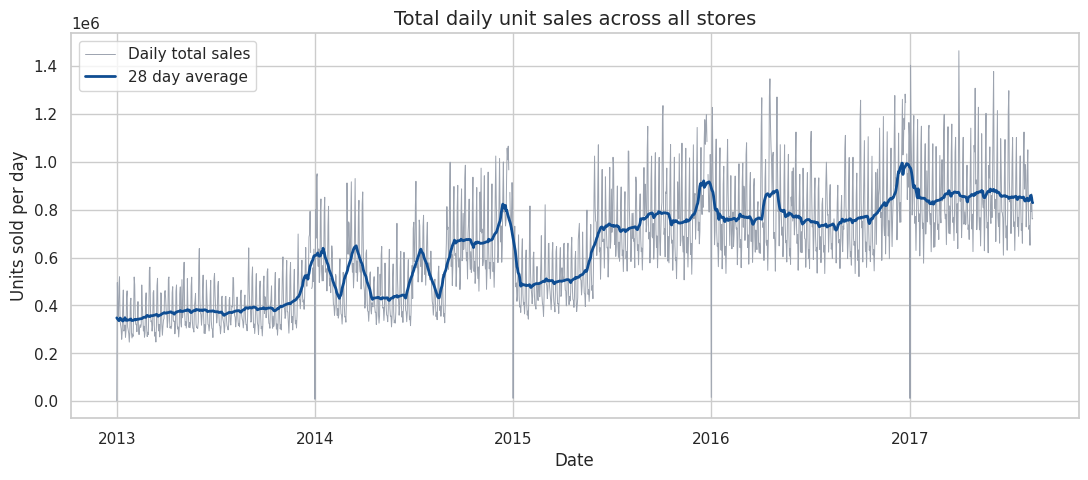

Average daily units, first full year vs most recent full year:
year
2013    385766.0
2014    575479.0
2015    661758.0
2016    790834.0
2017    855582.0


In [6]:
# Daily total sales across all stores and families.
daily_eda = train.groupby("date")["sales"].sum().asfreq("D").rename("sales").to_frame()   # closed days become NaN
daily_eda["year"] = daily_eda.index.year
daily_eda["month"] = daily_eda.index.month
daily_eda["day_of_week"] = daily_eda.index.dayofweek
daily_eda["day_of_month"] = daily_eda.index.day
# A centered 28 day average removes the weekly rhythm (28 is exactly four weeks), leaving the trend.
daily_eda["trend28"] = daily_eda["sales"].rolling(28, center=True, min_periods=14).mean()
daily_eda["ratio"] = daily_eda["sales"] / daily_eda["trend28"]    # 1.0 means a normal day for that period
recent_eda = daily_eda[daily_eda.index >= pd.Timestamp(2015, 1, 1)]   # early 2013 is distorted by stores opening

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(daily_eda.index, daily_eda["sales"], color=COLORS["naive"], linewidth=0.7, label="Daily total sales")
ax.plot(daily_eda.index, daily_eda["trend28"], color=COLORS["gbm"], linewidth=2, label="28 day average")
ax.set_title("Total daily unit sales across all stores")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend()
plt.show()
save_fig(fig, "eda_total_sales.png")
print("Average daily units, first full year vs most recent full year:")
print(daily_eda.groupby("year")["sales"].mean().round(0).to_string())

**How to read it:** the thin line is each day and the thick line smooths out the weekly noise to show the trend. Look for the overall direction, any sudden level shifts (store openings, unusual events) and the dips to near zero on closed days. The printed table gives the average daily units per year, and the last year shown is incomplete.

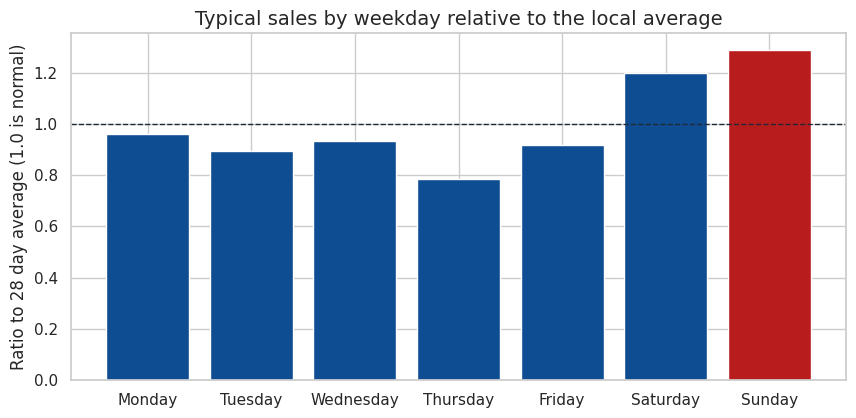

day_of_week
Monday       0.960
Tuesday      0.895
Wednesday    0.934
Thursday     0.786
Friday       0.918
Saturday     1.201
Sunday       1.291


In [7]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_ratio = recent_eda.groupby("day_of_week")["ratio"].mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(day_names, weekday_ratio.values, color=[COLORS["accent"] if v == weekday_ratio.max() else COLORS["gbm"] for v in weekday_ratio.values])
ax.axhline(1, color=COLORS["actual"], linestyle="--", linewidth=1)
ax.set_title("Typical sales by weekday relative to the local average")
ax.set_ylabel("Ratio to 28 day average (1.0 is normal)")
plt.show()
save_fig(fig, "eda_weekday.png")
print((weekday_ratio.round(3)).rename(dict(enumerate(day_names))).to_string())

**How to read it:** a bar above the dashed line means that weekday sells more than the average day. A strong, stable weekly shape is the main reason a "same weekday last week" baseline is hard to beat, and why the model needs weekday features and lags that are multiples of 7.

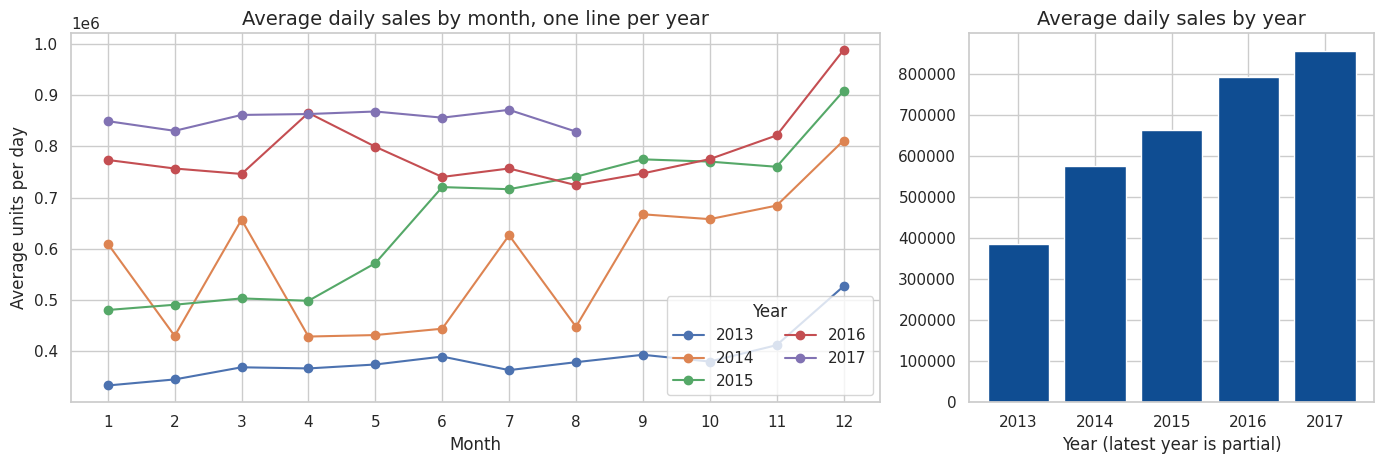

In [8]:
monthly = daily_eda.groupby(["year", "month"])["sales"].mean().unstack(0)
yearly = daily_eda.groupby("year")["sales"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2, 1]})
for year in monthly.columns:
    axes[0].plot(monthly.index, monthly[year], marker="o", linewidth=1.5, label=str(year))
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Average daily sales by month, one line per year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average units per day")
axes[0].legend(title="Year", ncol=2)
axes[1].bar(yearly.index.astype(str), yearly.values, color=COLORS["gbm"])
axes[1].set_title("Average daily sales by year")
axes[1].set_xlabel("Year (latest year is partial)")
plt.tight_layout()
plt.show()
save_fig(fig, "eda_seasonality_trend.png")

**How to read it:** the left chart shows the yearly shape by month. Months where the lines rise or fall together across years are seasonal patterns (for example December shopping). The right chart shows the long term growth. Growth means a model that only learned from old levels would under forecast, which is why recent history features matter.

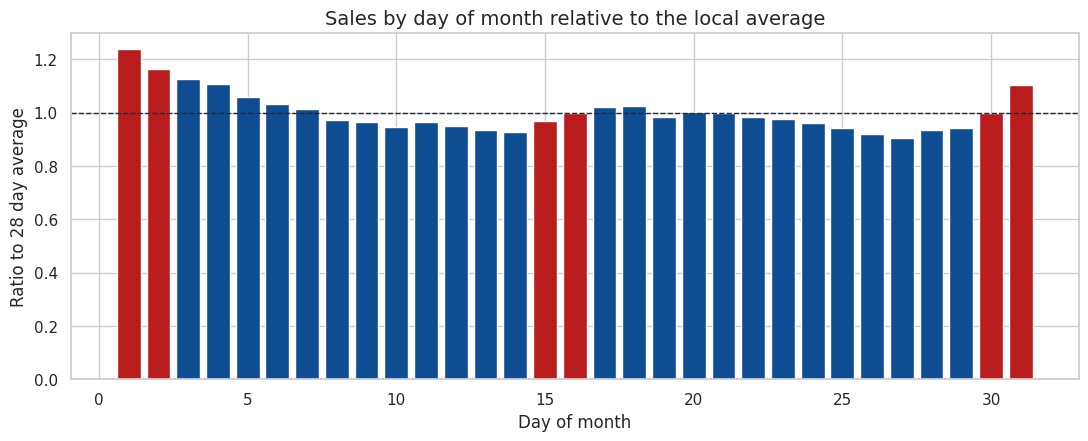

Five strongest days of the month: {1: 1.238, 2: 1.165, 3: 1.127, 4: 1.109, 31: 1.103}


In [9]:
clean_days = recent_eda[~((recent_eda["month"] == 1) & (recent_eda["day_of_month"] == 1))]   # exclude New Year, a special case
payday_ratio = clean_days.groupby("day_of_month")["ratio"].mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(payday_ratio.index, payday_ratio.values,
       color=[COLORS["accent"] if d in (1, 2, 15, 16, 30, 31) else COLORS["gbm"] for d in payday_ratio.index])
ax.axhline(1, color=COLORS["actual"], linestyle="--", linewidth=1)
ax.set_title("Sales by day of month relative to the local average")
ax.set_xlabel("Day of month")
ax.set_ylabel("Ratio to 28 day average")
plt.show()
save_fig(fig, "eda_payday.png")
print("Five strongest days of the month:", payday_ratio.sort_values(ascending=False).head(5).round(3).to_dict())

**How to read it:** public sector wages in Ecuador are paid on the 15th and on the last day of the month. If shoppers respond to payday, the bars around those days stand out from the rest. This is why the model gets a payday flag.

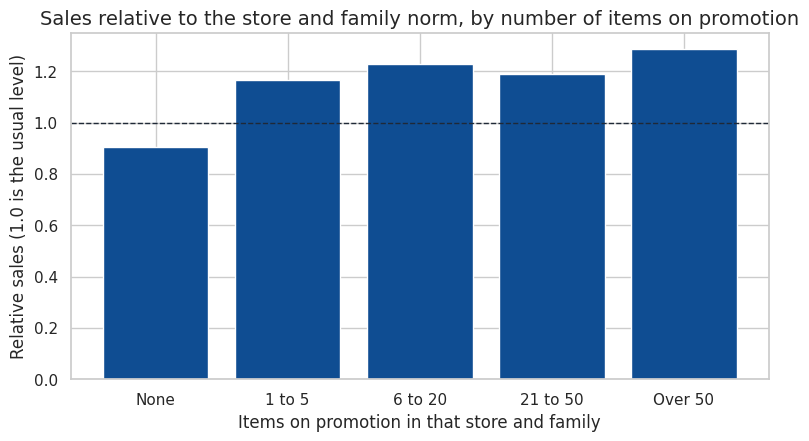

              mean    count
promo_level                
None         0.905  1105618
1 to 5       1.166   304643
6 to 20      1.227   141608
21 to 50     1.190    65296
Over 50      1.286    34803


In [10]:
# Promotions: compare sales on promoted rows with the usual level of the same store and family.
promo_view = train.loc[train["date"] >= pd.Timestamp(2015, 1, 1), ["store_nbr", "family_code", "sales", "onpromotion"]].copy()
promo_view["series_mean"] = promo_view.groupby(["store_nbr", "family_code"])["sales"].transform("mean")
promo_view = promo_view[promo_view["series_mean"] > 0]
promo_view["relative_sales"] = promo_view["sales"] / promo_view["series_mean"]
promo_view["promo_level"] = pd.cut(promo_view["onpromotion"], bins=[-0.5, 0.5, 5, 20, 50, np.inf],
                                   labels=["None", "1 to 5", "6 to 20", "21 to 50", "Over 50"])
promo_summary = promo_view.groupby("promo_level", observed=True)["relative_sales"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(promo_summary.index.astype(str), promo_summary["mean"], color=COLORS["gbm"])
ax.axhline(1, color=COLORS["actual"], linestyle="--", linewidth=1)
ax.set_title("Sales relative to the store and family norm, by number of items on promotion")
ax.set_xlabel("Items on promotion in that store and family")
ax.set_ylabel("Relative sales (1.0 is the usual level)")
plt.show()
save_fig(fig, "eda_promotions.png")
print(promo_summary.round(3).to_string())
del promo_view

**How to read it:** sales are divided by the usual level of the same store and family, so large families do not drown out small ones. Bars above 1 mean sales run above normal when promotions are active. This shows association, not proof of cause, because promotions are often planned for busy periods.

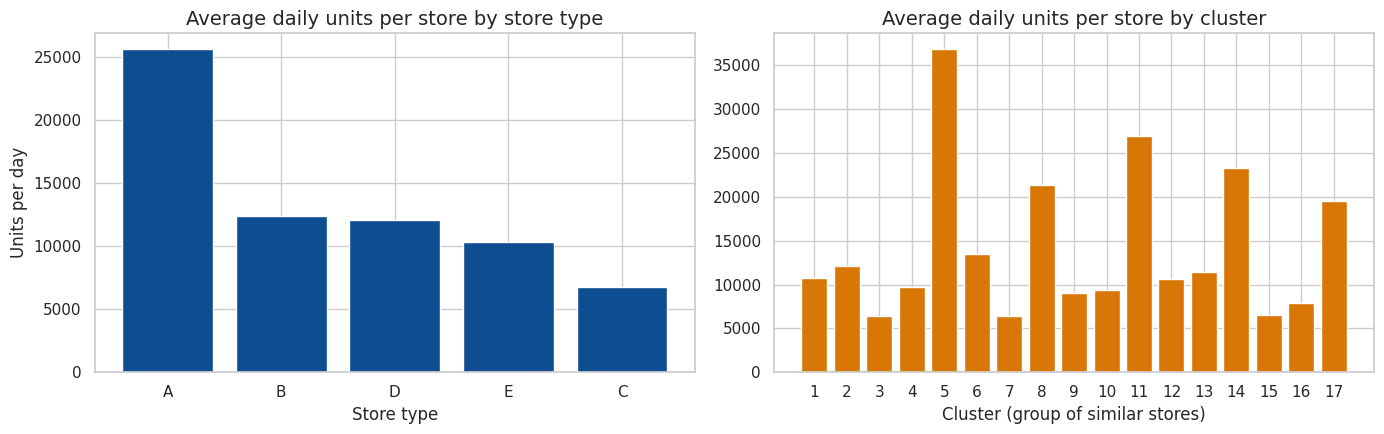

In [11]:
# Store format and cluster: average daily units per store since it opened.
days_open = (last_train_date - first_sale_date).dt.days + 1
store_perf = stores.set_index("store_nbr").join((train.groupby("store_nbr")["sales"].sum() / days_open).rename("avg_daily_units"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
type_perf = store_perf.groupby("type")["avg_daily_units"].mean().sort_values(ascending=False)
axes[0].bar(type_perf.index, type_perf.values, color=COLORS["gbm"])
axes[0].set_title("Average daily units per store by store type")
axes[0].set_xlabel("Store type")
axes[0].set_ylabel("Units per day")
cluster_perf = store_perf.groupby("cluster")["avg_daily_units"].mean().sort_index()
axes[1].bar(cluster_perf.index.astype(str), cluster_perf.values, color=COLORS["sarimax"])
axes[1].set_title("Average daily units per store by cluster")
axes[1].set_xlabel("Cluster (group of similar stores)")
plt.tight_layout()
plt.show()
save_fig(fig, "eda_store_type_cluster.png")

**How to read it:** stores differ a lot in size. Type and cluster describe groups of similar stores, so they are useful features that let the model share what it learns between comparable stores.

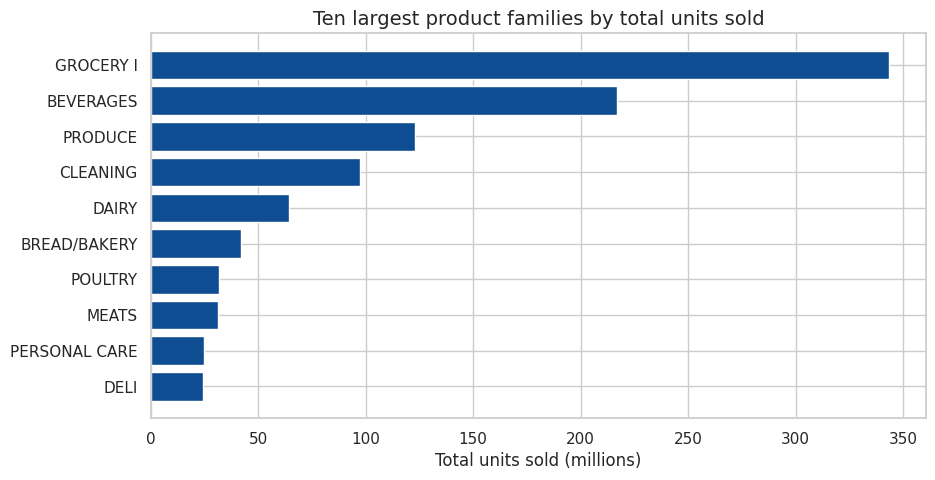

Share of all units from the top 3 families: 0.636


In [12]:
family_totals = train.groupby("family_code")["sales"].sum().rename(index=code_to_family).sort_values(ascending=False)
top_families = family_totals.head(10)[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_families.index, top_families.values / 1e6, color=COLORS["gbm"])
ax.set_title("Ten largest product families by total units sold")
ax.set_xlabel("Total units sold (millions)")
plt.show()
save_fig(fig, "eda_top_families.png")
share = family_totals / family_totals.sum()
print("Share of all units from the top 3 families:", round(float(share.head(3).sum()), 3))

**How to read it:** a few families make up most of the volume. Errors on these families matter most to the business, so the evaluation later reports WAPE, which weights each error by how many units are involved.

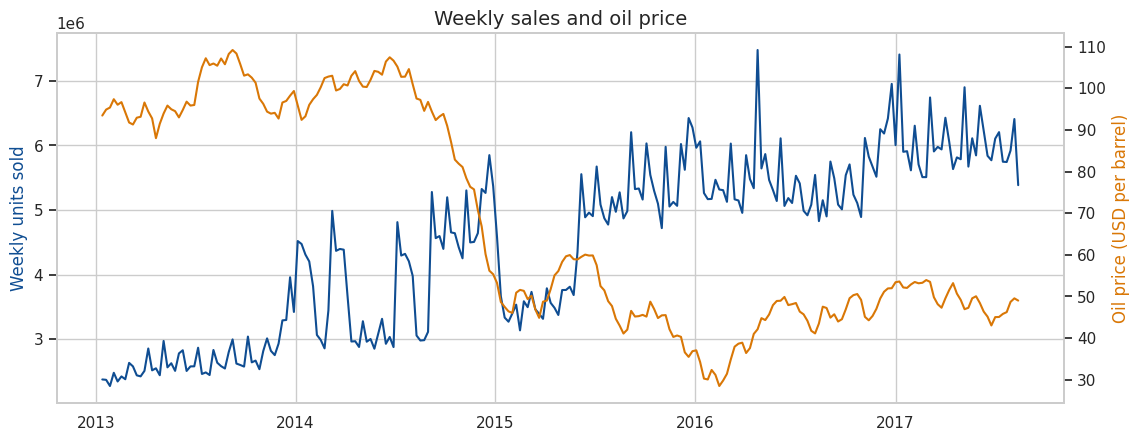

Correlation of levels: -0.771
Correlation of weekly changes: 0.022


In [13]:
# Oil: compare weekly sales with the weekly average oil price.
weekly = pd.DataFrame({
    "sales": daily_eda["sales"].resample("W").sum(),
    "oil": oil_daily.reindex(daily_eda.index).resample("W").mean(),
}).iloc[1:-1].dropna()

fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.plot(weekly.index, weekly["sales"], color=COLORS["gbm"], linewidth=1.5, label="Weekly sales")
ax1.set_ylabel("Weekly units sold", color=COLORS["gbm"])
ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly["oil"], color=COLORS["sarimax"], linewidth=1.5, label="Oil price")
ax2.set_ylabel("Oil price (USD per barrel)", color=COLORS["sarimax"])
ax2.grid(False)
ax1.set_title("Weekly sales and oil price")
plt.show()
save_fig(fig, "eda_oil.png")
print("Correlation of levels:", round(weekly["sales"].corr(weekly["oil"]), 3))
print("Correlation of weekly changes:", round(weekly["sales"].pct_change().corr(weekly["oil"].pct_change()), 3))

**How to read it:** two lines that trend can look related simply because both trend, so the correlation of levels can mislead. The correlation of weekly changes is the fairer test. A weak value for changes suggests oil has little short term power, so it is kept as a minor supporting feature.

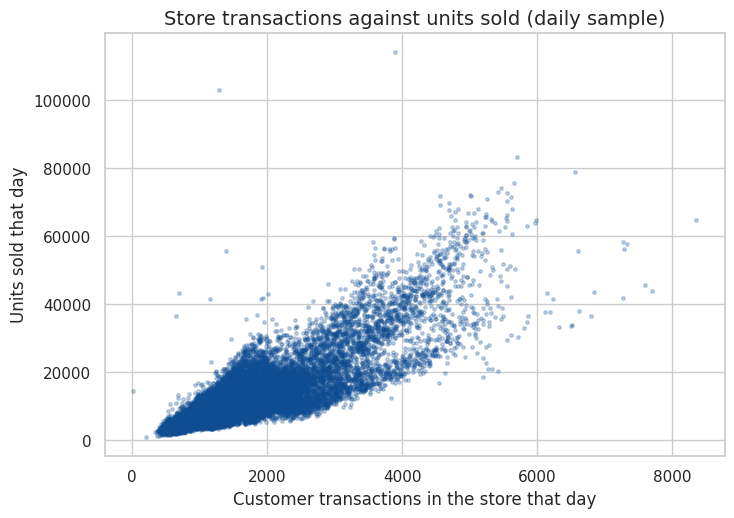

Correlation: 0.837


In [14]:
store_day = store_day_sales.merge(transactions, on=["store_nbr", "date"], how="inner")
sample_points = store_day.sample(min(20000, len(store_day)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(sample_points["transactions"], sample_points["sales"], s=6, alpha=0.25, color=COLORS["gbm"])
ax.set_title("Store transactions against units sold (daily sample)")
ax.set_xlabel("Customer transactions in the store that day")
ax.set_ylabel("Units sold that day")
plt.show()
save_fig(fig, "eda_transactions.png")
print("Correlation:", round(store_day["sales"].corr(store_day["transactions"]), 3))

**How to read it:** transactions track sales closely, which makes sense, but transactions are only known for the past. They cannot be used for the future days we forecast, so the model only uses transactions from at least 16 days earlier, as a measure of recent store traffic.

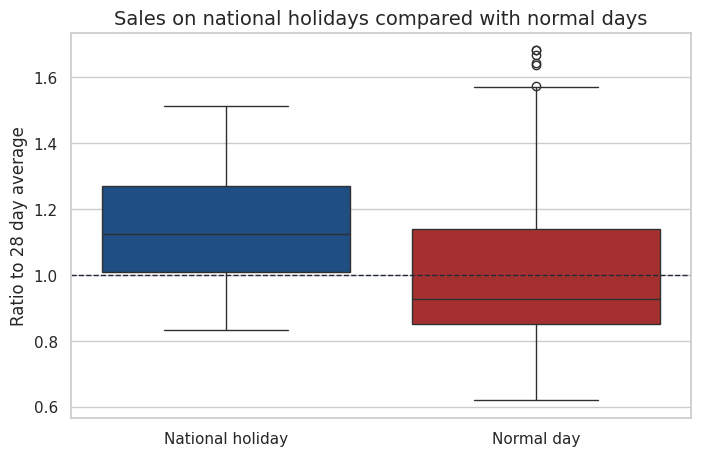

                   mean  median  count
day_type                              
National holiday  1.142   1.123     42
Normal day        0.994   0.927    911


In [15]:
national_flag = holiday_calendar.groupby("date")["holiday_national"].max().reindex(recent_eda.index)
holiday_view = recent_eda.assign(day_type=np.where(national_flag.fillna(0) == 1, "National holiday", "Normal day"))
holiday_view = holiday_view[~((holiday_view["month"] == 1) & (holiday_view["day_of_month"] == 1))]   # New Year is a near zero special case

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=holiday_view, x="day_type", y="ratio", palette=[COLORS["gbm"], COLORS["accent"]], ax=ax)
ax.axhline(1, color=COLORS["actual"], linestyle="--", linewidth=1)
ax.set_title("Sales on national holidays compared with normal days")
ax.set_xlabel("")
ax.set_ylabel("Ratio to 28 day average")
plt.show()
save_fig(fig, "eda_holidays.png")
print(holiday_view.groupby("day_type")["ratio"].agg(["mean", "median", "count"]).round(3).to_string())

**How to read it:** each box shows the spread of daily ratios. If the holiday box sits higher or lower than the normal box, holidays shift demand, and the direction tells you whether stores should stock up before them. Holidays also affect the days around them, which the lag features partly capture.

## 6. Feature engineering
Features are built in a wide layout first: one row per date and one column per store and family series. In this layout a lag or rolling window is a single fast operation across all 1,782 series at once, and it cannot accidentally mix one series into another.

**The leakage rule.** The forecast horizon is 16 days. When forecasting a day, the model must only use sales from at least 16 days earlier. So the shortest lag is 16 and every rolling window is calculated on sales that were first shifted by 16 days. This makes every validation score a true 16 day ahead score.

**Feature groups**

* **Calendar:** weekday, day of month, month, week of year, payday, month end, and a Christmas and New Year flag.
* **Holidays and events:** national holidays, store specific holidays, events.
* **Promotions:** number of items on promotion (the plan is known in advance).
* **Store and family:** store, family, cluster, type, city, state.
* **History:** sales 16, 21, 28, 35 and 364 days ago, plus a rolling mean and spread.
* **Context:** oil price and store transactions, both lagged by 16 days.

In [16]:
HORIZON = test["date"].nunique()      # number of future days to forecast
MIN_LAG = HORIZON                      # shortest history age that is always known at forecast time
print("Forecast horizon in days:", HORIZON)

# The full list of store and family series, in a fixed order.
series_keys = (train[["store_nbr", "family_code"]].drop_duplicates()
               .sort_values(["store_nbr", "family_code"]).reset_index(drop=True))
series_index = pd.MultiIndex.from_frame(series_keys)
n_dates, n_series = len(all_dates), len(series_keys)

def to_wide(frame, value):
    """Reshape long data to one row per date and one column per store and family series."""
    wide = frame.pivot(index="date", columns=["store_nbr", "family_code"], values=value)
    return wide.reindex(index=all_dates, columns=series_index)

sales_wide = to_wide(train, "sales")
# Days with no rows (such as 25 December) are closed days, so true sales were zero.
sales_wide.loc[:last_train_date] = sales_wide.loc[:last_train_date].fillna(0)

promo_source = pd.concat([train[["date", "store_nbr", "family_code", "onpromotion"]],
                          test[["date", "store_nbr", "family_code", "onpromotion"]]])
promo_wide = to_wide(promo_source, "onpromotion").fillna(0)

# History features. Every one of them is at least MIN_LAG days old.
history = {}
for lag in (16, 21, 28, 35, 364):
    history[f"sales_lag_{lag}"] = sales_wide.shift(lag)
known_sales = sales_wide.shift(MIN_LAG)          # sales as they would be known on forecast day
history["sales_roll_mean_7"] = known_sales.rolling(7, min_periods=3).mean()
history["sales_roll_mean_28"] = known_sales.rolling(28, min_periods=7).mean()
history["sales_roll_std_28"] = known_sales.rolling(28, min_periods=7).std()
print("Wide table shape (dates by series):", sales_wide.shape)

Forecast horizon in days: 16
Wide table shape (dates by series): (1704, 1782)


The wide tables are ready. Test days are empty in `sales_wide`, but because every feature is shifted by at least 16 days, the test rows still get complete features from real history. Next they are converted to a long table with one row per date, store and family, which is the layout the model trains on.

In [17]:
# Long table: dates repeat for each series, and series repeat for each date, matching the wide tables flattened row by row.
frame = pd.DataFrame({
    "date_idx": np.repeat(np.arange(n_dates, dtype="int32"), n_series),
    "series_id": np.tile(np.arange(n_series, dtype="int32"), n_dates),
})
frame["date"] = all_dates[frame["date_idx"].to_numpy()]
frame["store_nbr"] = np.tile(series_keys["store_nbr"].to_numpy(dtype="int16"), n_dates)
frame["family_code"] = np.tile(series_keys["family_code"].to_numpy(dtype="int16"), n_dates)
frame["sales"] = sales_wide.to_numpy(dtype="float32").ravel()
frame["onpromotion"] = promo_wide.to_numpy(dtype="float32").ravel()
for name, wide in history.items():
    frame[name] = wide.to_numpy(dtype="float32").ravel()

# Calendar features.
dt = frame["date"].dt
frame["day_of_week"] = dt.dayofweek.astype("int8")
frame["day_of_month"] = dt.day.astype("int8")
frame["month"] = dt.month.astype("int8")
frame["week_of_year"] = dt.isocalendar().week.astype("int8")
frame["is_month_end"] = dt.is_month_end.astype("int8")
frame["is_payday"] = ((dt.day == 15) | dt.is_month_end).astype("int8")
# Christmas Day and New Year are near zero sales days. A dedicated flag lets the model explain those zeros
# without wrongly learning that every national holiday means no sales.
frame["is_christmas_newyear"] = (((dt.month == 12) & (dt.day == 25)) | ((dt.month == 1) & (dt.day == 1))).astype("int8")

# Store descriptors converted to integer codes.
store_info = stores.copy()
for column in ("city", "state", "type"):
    store_info[f"{column}_code"] = store_info[column].astype("category").cat.codes.astype("int16")
store_info["cluster"] = store_info["cluster"].astype("int16")
frame = frame.merge(store_info[["store_nbr", "cluster", "type_code", "city_code", "state_code"]], on="store_nbr", how="left")

# Holidays and events for each store and date.
frame = frame.merge(holiday_calendar, on=["date", "store_nbr"], how="left")
for column in ("holiday_national", "holiday_local", "is_holiday", "is_event"):
    frame[column] = frame[column].fillna(0).astype("int8")

# Oil price, lagged so that only a price known 16 days earlier is used.
frame["oil_lag_16"] = frame["date"].map(oil_daily.shift(MIN_LAG)).astype("float32")

# Store transactions, lagged by 16 days, plus a 28 day average of that lagged traffic.
transactions_wide = transactions.pivot(index="date", columns="store_nbr", values="transactions").reindex(all_dates)
transactions_known = transactions_wide.shift(MIN_LAG)

def wide_to_long(wide, value_name):
    out = wide.copy()
    out.index.name = "date"
    out.columns.name = "store_nbr"
    return out.reset_index().melt(id_vars="date", var_name="store_nbr", value_name=value_name)

transactions_long = wide_to_long(transactions_known, "transactions_lag_16").merge(
    wide_to_long(transactions_known.rolling(28, min_periods=7).mean(), "transactions_roll_mean_28"),
    on=["date", "store_nbr"])
transactions_long["store_nbr"] = transactions_long["store_nbr"].astype("int16")
frame = frame.merge(transactions_long, on=["date", "store_nbr"], how="left")
for column in ("transactions_lag_16", "transactions_roll_mean_28"):
    frame[column] = frame[column].astype("float32")

# Row flags used for filtering later.
frame["open_date"] = frame["store_nbr"].map(first_sale_date)
frame["is_open_period"] = frame["date"] >= frame["open_date"]     # False before a store started selling
frame["is_train"] = frame["date"] <= last_train_date
assert len(frame) == n_dates * n_series, "Row count changed during merges"
print("Feature table shape:", frame.shape)

Feature table shape: (3036528, 36)


In [18]:
feature_columns = [
    "day_of_week", "day_of_month", "month", "week_of_year", "is_month_end", "is_payday", "is_christmas_newyear",
    "holiday_national", "holiday_local", "is_holiday", "is_event",
    "onpromotion",
    "store_nbr", "family_code", "cluster", "type_code", "city_code", "state_code",
    "sales_lag_16", "sales_lag_21", "sales_lag_28", "sales_lag_35", "sales_lag_364",
    "sales_roll_mean_7", "sales_roll_mean_28", "sales_roll_std_28",
    "oil_lag_16", "transactions_lag_16", "transactions_roll_mean_28",
]
# Columns that are labels rather than quantities, so the model should treat them as categories.
categorical_names = ["day_of_week", "month", "week_of_year", "store_nbr", "family_code",
                     "cluster", "type_code", "city_code", "state_code"]
categorical_mask = [column in categorical_names for column in feature_columns]

# Rows the model may learn from: real history, after the store opened, with the longest short lag available.
trainable = frame["is_train"] & frame["is_open_period"] & frame["sales_lag_35"].notna()
print("Training rows available:", int(trainable.sum()))
print("Number of features:", len(feature_columns))

Training rows available: 2733819
Number of features: 29


Every feature is known at forecast time, and training rows come only from real selling history. Missing values in lag features (early in a series, or lag 364 in the first year) are handled natively by the gradient boosting model, so they are left as they are.

## 7. Validation design
All splits respect time. The model never trains on days after the period it is tested on, and rows are never shuffled.

There are four validation folds. Each fold forecasts 16 days using only data up to the day before it begins. Fold 1 is the most recent 16 days of train, which is the situation closest to the real test window. Folds 2 to 4 step back 16 days each, to show whether performance is stable or whether Fold 1 was just lucky.

A random split would mix future and past days in the training set and give a flattering but meaningless score.

In [19]:
folds = []
for k in range(4):
    val_end = len(train_calendar) - k * HORIZON
    val_start = val_end - HORIZON
    folds.append({
        "name": f"Fold {k + 1}",
        "origin": train_calendar[val_start - 1],          # last day the model is allowed to know
        "val_dates": train_calendar[val_start:val_end],
    })
fold_table = pd.DataFrame([{"fold": f["name"], "training ends": f["origin"].date(),
                            "validation starts": f["val_dates"][0].date(),
                            "validation ends": f["val_dates"][-1].date()} for f in folds])
fold_table

,fold,training ends,validation starts,validation ends
0,Fold 1,2017-07-30,2017-07-31,2017-08-15
1,Fold 2,2017-07-14,2017-07-15,2017-07-30
2,Fold 3,2017-06-28,2017-06-29,2017-07-14
3,Fold 4,2017-06-12,2017-06-13,2017-06-28


## 8. Baseline and models

**Seasonal naive baseline.** Predict each day with the most recent same weekday that was known at the forecast origin.if the final known was wednesday and you are trying to predict thursday, go back to the most recent known thursday. It needs no training, so it sets the minimum standard any real model must beat.

**Three gradient boosting models.** Each is trained once across all store and family series. Series with little history borrow patterns from similar series, and a few global models are far easier to maintain than 1,782 separate ones. The three members are deliberately different:

1. **Gradient boosting (scikit learn) on log1p(sales).** The log target stops the biggest families from dominating training, so small and large series are treated fairly. Predictions are converted back with `expm1` and negative values are clipped to zero.
2. **LightGBM with a Tweedie loss on raw sales.** Sales are non negative counts with many zeros, which is what the Tweedie loss is designed for. It learns on the unit scale, so it pays more attention to large series, which makes its errors different from member 1.
3. **Recent gradient boosting.** The same model as member 1, trained only on the last two years. It adapts faster to the current level and ignores the period when stores were still opening.

**The ensemble** is the simple average of the three predictions. Averaging helps when models make different mistakes, because the mistakes partly cancel. Equal weights are used on purpose, since choosing weights from only four validation folds would risk fitting noise. One honest caveat is that members 1 and 3 are the same algorithm, so their errors are related. The ensemble checks in section 9 measure how much diversity there really is.

In [20]:
sales_array = sales_wide.to_numpy(dtype="float32")   # dates by series lookup used by the baseline
GBM_ITERATIONS = 250                                  # lower this for a faster run, raise it for a slightly better fit

def seasonal_naive_prediction(rows, origin):
    """Same weekday sales from the latest week that was known at the forecast origin."""
    origin_idx = all_dates.get_loc(origin)
    days_ahead = rows["date_idx"].to_numpy() - origin_idx
    weeks_back = np.ceil(days_ahead / 7).astype(int)
    source_idx = rows["date_idx"].to_numpy() - 7 * weeks_back
    return np.clip(sales_array[source_idx, rows["series_id"].to_numpy()], 0, None)

def design_matrix(rows):
    return rows[feature_columns].to_numpy(dtype="float32")

def fit_gbm(train_rows):
    """Train the global gradient boosting model on the log of sales."""
    model = HistGradientBoostingRegressor(
        learning_rate=0.1, max_iter=GBM_ITERATIONS, max_leaf_nodes=63, min_samples_leaf=100,
        l2_regularization=1.0, categorical_features=categorical_mask,
        early_stopping=False, random_state=RANDOM_STATE)
    model.fit(design_matrix(train_rows), np.log1p(train_rows["sales"].to_numpy()))
    return model

def predict_gbm(model, rows):
    return np.clip(np.expm1(model.predict(design_matrix(rows))), 0, None)

def fit_lgbm(train_rows):
    """LightGBM on raw sales with a Tweedie loss, which suits non negative counts with many zeros."""
    model = lgb.LGBMRegressor(
        objective="tweedie", tweedie_variance_power=1.3, n_estimators=400, learning_rate=0.05,
        num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    model.fit(train_rows[feature_columns], train_rows["sales"], categorical_feature=categorical_names)
    return model

def predict_lgbm(model, rows):
    return np.clip(model.predict(rows[feature_columns]), 0, None)

def fit_gbm_recent(train_rows):
    """Same model as the main one, trained only on the last two years of rows."""
    cutoff = train_rows["date_idx"].max() - 730
    return fit_gbm(train_rows[train_rows["date_idx"] > cutoff])

## 9. Evaluation
Three metrics are reported on the store and family level predictions.

* **MAE** is the average miss in units per store, family and day.
* **WAPE** is total absolute error divided by total actual sales. It reads as "the percentage of volume we missed" and weights big families more, so it matches business impact.
* **RMSLE** is the Kaggle competition metric. It measures errors in proportion, so a miss on a small series counts about as much as the same percentage miss on a large one.

In [21]:
def metric_row(actual, predicted, model_name, fold_name):
    actual = np.asarray(actual, dtype="float64")
    predicted = np.clip(np.asarray(predicted, dtype="float64"), 0, None)
    return {
        "model": model_name, "fold": fold_name,
        "MAE": np.mean(np.abs(actual - predicted)),
        "WAPE": np.abs(actual - predicted).sum() / max(actual.sum(), 1.0),
        "RMSLE": np.sqrt(np.mean((np.log1p(actual) - np.log1p(predicted)) ** 2)),
    }

fold_predictions = {}      # per fold store family predictions, reused for error analysis and the total level comparison
metric_rows = []
fold_one_model = None
for fold in folds:
    origin_idx = all_dates.get_loc(fold["origin"])
    train_rows = frame.loc[trainable & (frame["date_idx"] <= origin_idx)]
    val_rows = frame.loc[(frame["date_idx"] > origin_idx) & (frame["date_idx"] <= origin_idx + HORIZON) & frame["is_open_period"]]

    model = fit_gbm(train_rows)
    gbm_pred = predict_gbm(model, val_rows)
    lgbm_pred = predict_lgbm(fit_lgbm(train_rows), val_rows)
    recent_pred = predict_gbm(fit_gbm_recent(train_rows), val_rows)
    ensemble_pred = (gbm_pred + lgbm_pred + recent_pred) / 3
    naive_pred = seasonal_naive_prediction(val_rows, fold["origin"])

    metric_rows.append(metric_row(val_rows["sales"], naive_pred, "Seasonal naive", fold["name"]))
    metric_rows.append(metric_row(val_rows["sales"], gbm_pred, "Gradient boosting", fold["name"]))
    metric_rows.append(metric_row(val_rows["sales"], lgbm_pred, "LightGBM Tweedie", fold["name"]))
    metric_rows.append(metric_row(val_rows["sales"], recent_pred, "Gradient boosting recent", fold["name"]))
    metric_rows.append(metric_row(val_rows["sales"], ensemble_pred, "Ensemble average", fold["name"]))

    
    keep = val_rows[["date", "store_nbr", "family_code", "sales", "is_holiday", "date_idx", "series_id"]].copy()
    keep["gbm"] = gbm_pred
    keep["lgbm"] = lgbm_pred
    keep["recent"] = recent_pred
    keep["ensemble"] = ensemble_pred
    keep["naive"] = naive_pred
    
    fold_predictions[fold["name"]] = keep
    if fold["name"] == "Fold 1":
        fold_one_model, fold_one_rows = model, val_rows
    print(f"{fold['name']} finished. Training rows: {len(train_rows):,}")

results = pd.DataFrame(metric_rows)
display(results.round(4))
display(results.groupby("model")[["MAE", "WAPE", "RMSLE"]].mean().round(4).rename_axis("Average over 4 folds"))

Fold 1 finished. Training rows: 2,705,307
Fold 2 finished. Training rows: 2,676,795
Fold 3 finished. Training rows: 2,648,283
Fold 4 finished. Training rows: 2,619,771


,model,fold,MAE,WAPE,RMSLE
0,Seasonal naive,Fold 1,96.5354,0.2067,0.6170
1,Gradient boosting,Fold 1,60.2223,0.1289,0.4085
2,LightGBM Tweedie,Fold 1,57.2084,0.1225,0.4280
3,Gradient boosting recent,Fold 1,61.1980,0.1310,0.4131
4,Ensemble average,Fold 1,57.5776,0.1233,0.4095
5,Seasonal naive,Fold 2,67.2942,0.1397,0.5212
6,Gradient boosting,Fold 2,63.1418,0.1311,0.4069
7,LightGBM Tweedie,Fold 2,58.6717,0.1218,0.4144
8,Gradient boosting recent,Fold 2,60.5168,0.1256,0.4165
9,Ensemble average,Fold 2,58.8498,0.1222,0.4029


,MAE,WAPE,RMSLE
Average over 4 folds,,,
Ensemble average,54.8253,0.1161,0.3974
Gradient boosting,58.1347,0.1230,0.3976
Gradient boosting recent,57.2210,0.1211,0.4025
LightGBM Tweedie,55.1298,0.1167,0.4147
Seasonal naive,79.9761,0.1695,0.5448


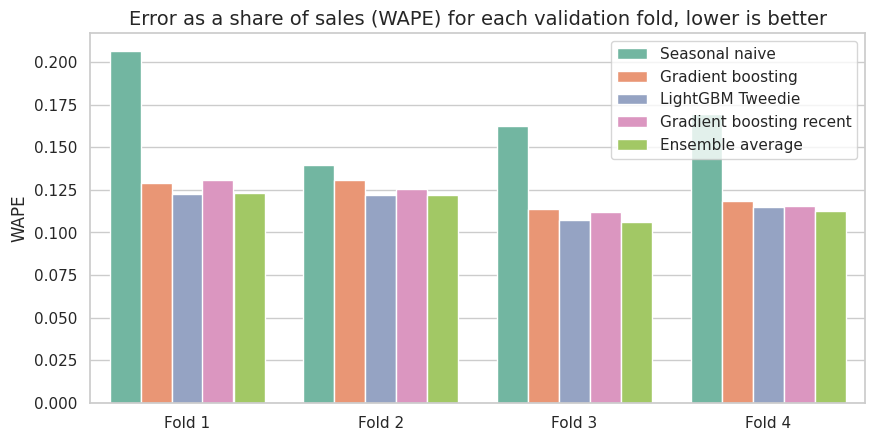

In [22]:
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=results, x="fold", y="WAPE", hue="model", palette="Set2", ax=ax)
ax.set_title("Error as a share of sales (WAPE) for each validation fold, lower is better")
ax.set_xlabel("")
ax.set_ylabel("WAPE")
ax.legend(title="")
plt.show()
save_fig(fig, "evaluation_wape_by_fold.png")

**How to read it:** each fold is a separate 16 day forecast test, so a model that is better in every fold, not just one, is genuinely better. Compare the ensemble with each single model. In our run it beat the original gradient boosting model in every fold on WAPE, but LightGBM alone came close and won some folds, so the main benefit of the ensemble is stability rather than a large jump in accuracy. LightGBM scored worse on RMSLE because it trains on raw units and cares less about small series, while the ensemble stayed close to the log model on that metric. With only four folds of 16 days, treat differences of about half a percentage point or less as ties. These are honest 16 day ahead scores, so they look less impressive than next day scores, but they reflect real use.

In [23]:
import pandas as pd
members = ["gbm", "lgbm", "recent"]
all_folds = pd.concat([df.assign(fold=name) for name, df in fold_predictions.items()], ignore_index=True)
# Bring in the 28 day history feature so we can test the zero rule below.
all_folds = all_folds.merge(frame[["date_idx", "series_id", "sales_roll_mean_28"]], on=["date_idx", "series_id"], how="left")

# 1. Diversity: how correlated are the members' errors on the log scale? Lower correlation means more to gain from averaging.
log_errors = pd.DataFrame({m: np.log1p(all_folds[m]) - np.log1p(all_folds["sales"]) for m in members})
print("Correlation of member errors (log scale):")
display(log_errors.corr().round(3))

# 2. Other ways to combine the members. The geometric average works on the log scale, which matches RMSLE.
blends = {
    "Ensemble: equal average": all_folds[members].mean(axis=1),
    "Ensemble: geometric average": np.expm1(np.log1p(all_folds[members]).mean(axis=1)),
    "Without recent": all_folds[["gbm", "lgbm"]].mean(axis=1),
    "Without LightGBM": all_folds[["gbm", "recent"]].mean(axis=1),
}

# 3. Zero rule: a series with no sales in its last known 28 days is predicted as zero.
stopped = all_folds["sales_roll_mean_28"].eq(0)
print("Rows affected by the zero rule:", int(stopped.sum()), "of", len(all_folds))
blends["Equal average plus zero rule"] = blends["Ensemble: equal average"].where(~stopped, 0.0)

rows = []
for name, prediction in blends.items():
    for fold_name, part in all_folds.groupby("fold"):
        rows.append(metric_row(part["sales"], prediction.loc[part.index], name, fold_name))
display(pd.DataFrame(rows).groupby("model")[["MAE", "WAPE", "RMSLE"]].mean().round(4).sort_values("WAPE"))

Correlation of member errors (log scale):


,gbm,lgbm,recent
gbm,1.000,0.953,0.975
lgbm,0.953,1.000,0.940
recent,0.975,0.940,1.000


Rows affected by the zero rule: 6859 of 114048


,MAE,WAPE,RMSLE
model,,,
Ensemble: equal average,54.8253,0.1161,0.3974
Ensemble: geometric average,54.8442,0.1161,0.3974
Equal average plus zero rule,54.8249,0.1161,0.3987
Without recent,55.1095,0.1167,0.4001
Without LightGBM,56.1502,0.1188,0.3972


**How to read it:** the correlation table shows how alike the members' mistakes are. If two members are very highly correlated (for example above 0.95), they behave like one model, and the ensemble is effectively built from fewer models than it appears. The second table compares ways of combining them on the average of the four folds. Only adopt a different average or the zero rule if it improves WAPE or RMSLE clearly and in most folds, not by a rounding difference. The simple equal average is the default because it is easy to explain and hard to overfit.

## 10. Error analysis
A single score hides where the model struggles. Using the most recent fold, errors are broken down by store type, product family and holiday versus normal days.

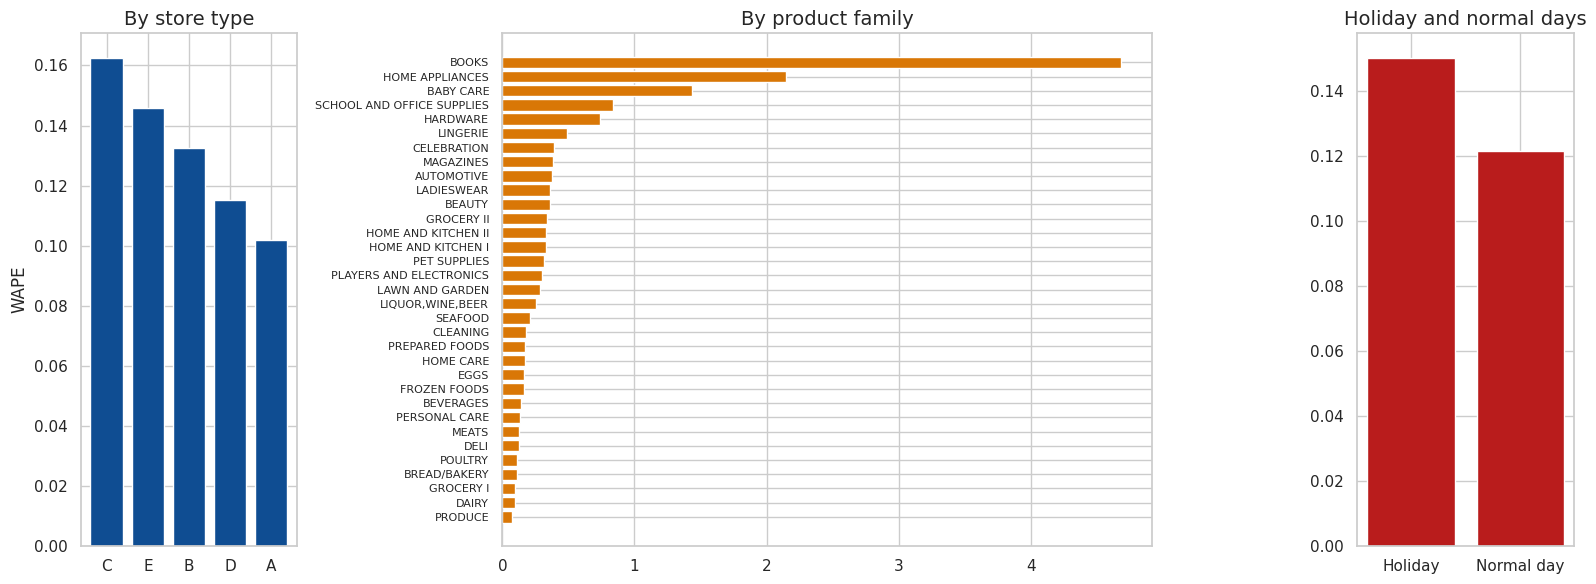

Families with the highest error and their share of total sales:
                             WAPE  share_of_sales
family                                           
BOOKS                       4.685           0.000
HOME APPLIANCES             2.149           0.000
BABY CARE                   1.439           0.000
SCHOOL AND OFFICE SUPPLIES  0.838           0.004
HARDWARE                    0.737           0.000


In [24]:
errors = fold_predictions["Fold 1"].merge(stores[["store_nbr", "type"]], on="store_nbr", how="left")
errors["family"] = errors["family_code"].map(code_to_family)
errors["abs_error"] = (errors["sales"] - errors["ensemble"]).abs()
errors["day_type"] = np.where(errors["is_holiday"] == 1, "Holiday", "Normal day")

def wape_by(df, column):
    grouped = df.groupby(column).agg(abs_error=("abs_error", "sum"), actual=("sales", "sum"))
    grouped["WAPE"] = grouped["abs_error"] / grouped["actual"].clip(lower=1)
    grouped["share_of_sales"] = grouped["actual"] / grouped["actual"].sum()
    return grouped.sort_values("WAPE", ascending=False)

by_type = wape_by(errors, "type")
by_family = wape_by(errors, "family")
by_day_type = wape_by(errors, "day_type")

fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 3, 1]})
axes[0].bar(by_type.index, by_type["WAPE"], color=COLORS["gbm"])
axes[0].set_title("By store type")
axes[0].set_ylabel("WAPE")
family_plot = by_family.sort_values("WAPE")
axes[1].barh(family_plot.index, family_plot["WAPE"], color=COLORS["sarimax"])
axes[1].set_title("By product family")
axes[1].tick_params(axis="y", labelsize=8)
axes[2].bar(by_day_type.index, by_day_type["WAPE"], color=COLORS["accent"])
axes[2].set_title("Holiday and normal days")
plt.tight_layout()
plt.show()
save_fig(fig, "error_analysis.png")
print("Families with the highest error and their share of total sales:")
print(by_family.head(5)[["WAPE", "share_of_sales"]].round(3).to_string())

**How to read it:** these errors are for the ensemble on the most recent fold. Families with high WAPE are usually small, erratic or sparse (many zero days), so their share of total sales shows how much the weakness matters in practice. In our run the families with the highest error held close to zero percent of sales, so they matter little for ordering decisions, but they do inflate unweighted metrics such as RMSLE. A gap between holiday and normal days shows how well the model handles special dates.

## 11. Feature importance
Permutation importance shuffles one feature at a time on validation data and measures how much the model gets worse. A feature that causes a large drop when shuffled is one the model truly relies on. This is more trustworthy than built in importance scores for tree models.

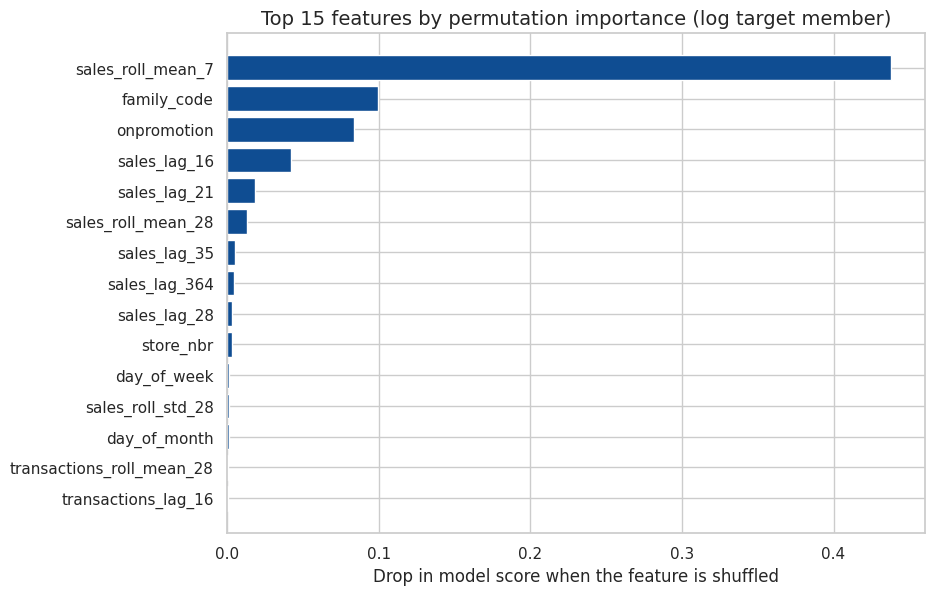

,feature,importance
23,sales_roll_mean_7,0.4382
13,family_code,0.0996
11,onpromotion,0.0840
18,sales_lag_16,0.0424
19,sales_lag_21,0.0182
24,sales_roll_mean_28,0.0129
21,sales_lag_35,0.0052
22,sales_lag_364,0.0047


In [25]:
importance_sample = fold_one_rows.sample(min(15000, len(fold_one_rows)), random_state=RANDOM_STATE)
importance = permutation_importance(
    fold_one_model, design_matrix(importance_sample), np.log1p(importance_sample["sales"].to_numpy()),
    n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance_table = (pd.DataFrame({"feature": feature_columns, "importance": importance.importances_mean})
                    .sort_values("importance", ascending=False))

fig, ax = plt.subplots(figsize=(9, 6.5))
top_features = importance_table.head(15)[::-1]
ax.barh(top_features["feature"], top_features["importance"], color=COLORS["gbm"])
ax.set_title("Top 15 features by permutation importance (log target member)")
ax.set_xlabel("Drop in model score when the feature is shuffled")
plt.show()
save_fig(fig, "feature_importance.png")
importance_table.head(8).round(4)

**How to read it:** the longer the bar, the more the forecast depends on that feature. This is computed on the log target gradient boosting member only. The three members share the same features, so the picture should be similar, though LightGBM may rank some features differently. In our run recent sales history (the rolling average and the lags) mattered most, followed by the product family and the number of items on promotion. In business terms, the forecast mostly follows recent demand, adjusted for what kind of product it is and whether it is on promotion.

## 12. Classical time series modelling with SARIMAX (total sales)

The gradient boosting model learns patterns across thousands of series. A classical model such as ARIMA works on **one series at a time**, and it is worth learning because it explains time series structure very clearly. We apply it to total daily sales across all stores, where there is a single smooth series with strong structure.

**What the name means**

* **AR (autoregressive, order p):** today depends on the last p days.
* **I (integrated, order d):** differencing, which subtracts yesterday from today to remove the trend.
* **MA (moving average, order q):** today depends on the last q forecast errors.
* **Seasonal part (P, D, Q, 7):** the same ideas applied at a lag of 7 days, to capture the weekly cycle.
* **X (exogenous):** extra known inputs, here holidays, payday and promotions.

**Modelling choices**

* We model `log1p(total sales)`. On a log scale a weekly swing of 20 percent is the same size whether sales are low or high, which suits a growing series.
* We use data from 2015 onward. In 2013 and 2014 stores were still opening, which creates level jumps that ARIMA would have to explain.
* Closed days (25 December) are set to missing in the model data, which the state space method handles correctly, instead of treating a zero as a real sales value.

In [26]:
SARIMAX_START = pd.Timestamp(2015, 1, 1)

def make_daily_frame(rows):
    """Aggregate store and family rows into one daily series with the regressors SARIMAX will use."""
    daily = rows.groupby("date").agg(sales=("sales", "sum"), promo=("onpromotion", "sum"),
                                     holiday_share=("is_holiday", "mean"), is_payday=("is_payday", "max"))
    daily = daily.asfreq("D")
    daily.loc[daily.index > last_train_date, "sales"] = np.nan          # future days have no sales yet
    closed = daily["sales"].eq(0)                                        # stores shut, not a real demand value
    daily["y"] = np.log1p(daily["sales"].where(~closed))
    daily["is_jan1"] = ((daily.index.month == 1) & (daily.index.day == 1)).astype(int)
    history_mask = daily.index <= last_train_date
    daily["promo_z"] = (daily["promo"] - daily.loc[history_mask, "promo"].mean()) / daily.loc[history_mask, "promo"].std()
    daily["holiday_share"] = daily["holiday_share"].astype(float)
    daily["is_payday"] = daily["is_payday"].astype(float)
    return daily

EXOG_COLUMNS = ["holiday_share", "is_payday", "is_jan1", "promo_z"]
daily_total = make_daily_frame(frame)
total_model_data = daily_total.loc[SARIMAX_START:]
total_model_data[["sales", "holiday_share", "is_payday", "promo_z"]].tail(3)

,sales,holiday_share,is_payday,promo_z
date,,,,
2017-08-29,NaN,0.0,0.0,1.153588
2017-08-30,NaN,0.0,0.0,3.113201
2017-08-31,NaN,0.0,1.0,1.228354


### Step 1: is the series stationary?
ARIMA needs a series whose average level and spread do not drift. The Augmented Dickey Fuller test checks this. A small p value (below 0.05) supports stationarity. We test the raw log series, then after ordinary differencing, then after also differencing at lag 7.

In [27]:
y_total = total_model_data.loc[:last_train_date, "y"]
stationarity = {}
for label, series in [("Log sales", y_total),
                      ("After 1 difference (d = 1)", y_total.diff()),
                      ("After 1 difference and 1 weekly difference (d = 1, D = 1)", y_total.diff().diff(7))]:
    statistic, p_value = adfuller(series.dropna())[:2]
    stationarity[label] = {"ADF statistic": round(statistic, 2), "p value": round(p_value, 4), "Stationary at 5 percent": p_value < 0.05}
pd.DataFrame(stationarity).T

,ADF statistic,p value,Stationary at 5 percent
Log sales,-2.78,0.0614,False
After 1 difference (d = 1),-12.7,0.0,True
"After 1 difference and 1 weekly difference (d = 1, D = 1)",-14.66,0.0,True


**How to read it:** if the raw series has a large p value and the differenced versions have small ones, differencing is needed. That is why every candidate model below uses `d = 1` and `D = 1`.

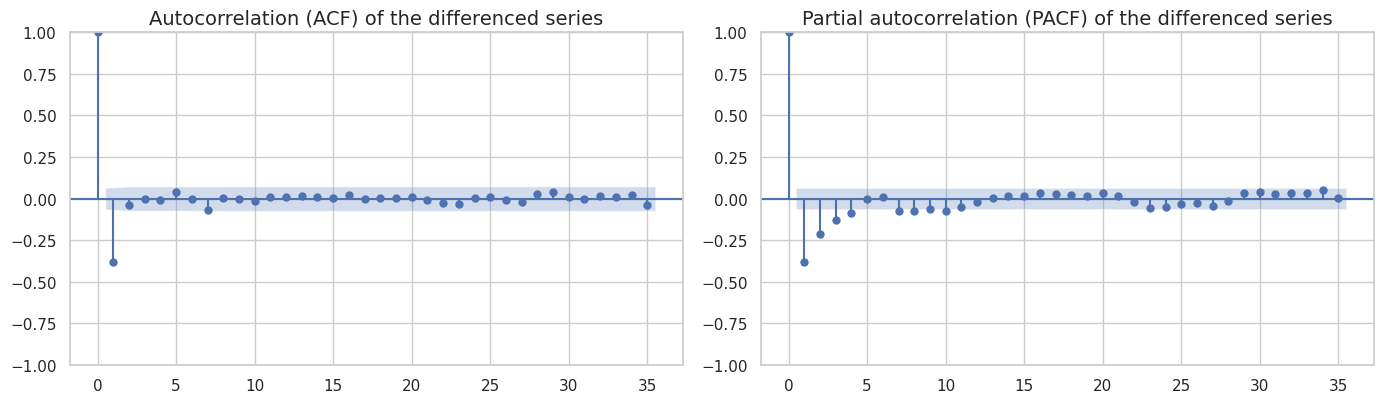

In [28]:
differenced = y_total.diff().diff(7).dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
plot_acf(differenced, lags=35, ax=axes[0])
plot_pacf(differenced, lags=35, ax=axes[1], method="ywm")
axes[0].set_title("Autocorrelation (ACF) of the differenced series")
axes[1].set_title("Partial autocorrelation (PACF) of the differenced series")
plt.tight_layout()
plt.show()
save_fig(fig, "sarimax_acf_pacf.png")

**How to read it:** the bars show how strongly the series relates to itself at each lag, and bars outside the shaded band are significant. Spikes at lags 1, 2, 3 suggest the short term AR or MA orders, and spikes at lags 7, 14, 21 suggest the seasonal orders. These plots guide which small candidate models to compare, and the final choice is made by AIC below. AIC rewards fit and penalises complexity, so lower is better.

In [29]:
CANDIDATE_ORDERS = [
    ((1, 1, 1), (0, 1, 1, 7)),
    ((2, 1, 1), (0, 1, 1, 7)),
    ((1, 1, 2), (0, 1, 1, 7)),
    ((1, 1, 1), (1, 1, 1, 7)),
    ((0, 1, 1), (0, 1, 1, 7)),
]

def fit_sarimax(y, exog, order, seasonal_order):
    """Fit one SARIMAX model."""
    model = SARIMAX(y, exog=exog, order=order, seasonal_order=seasonal_order,
                    enforce_stationarity=False, enforce_invertibility=False)
    return model.fit(disp=False, maxiter=60)

def select_order(daily, selection_end):
    """Compare the candidate models by AIC using only data up to selection_end."""
    window = daily.loc[SARIMAX_START:selection_end]
    rows = []
    for order, seasonal_order in CANDIDATE_ORDERS:
        result = fit_sarimax(window["y"], window[EXOG_COLUMNS], order, seasonal_order)
        rows.append({"order": order, "seasonal_order": seasonal_order, "AIC": round(result.aic, 1)})
    table = pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)
    best = (table.loc[0, "order"], table.loc[0, "seasonal_order"])
    return table, best

# The order is chosen using data that ends before the earliest validation fold, so the choice never sees any validation day.
selection_end = min(f["origin"] for f in folds)
total_order_table, total_best = select_order(daily_total, selection_end)
print("Best candidate by AIC:", total_best)
total_order_table

Best candidate by AIC: ((2, 1, 1), (0, 1, 1, 7))


,order,seasonal_order,AIC
0,"(2, 1, 1)","(0, 1, 1, 7)",-1727.1
1,"(1, 1, 2)","(0, 1, 1, 7)",-1726.4
2,"(1, 1, 1)","(0, 1, 1, 7)",-1719.7
3,"(1, 1, 1)","(1, 1, 1, 7)",-1718.7
4,"(0, 1, 1)","(0, 1, 1, 7)",-1618.1


The order with the lowest AIC is carried forward. Now the chosen model is refitted for each validation fold on only the data known at that fold's origin, then asked to forecast the same 16 days the tree models forecasts.

In [30]:
def sarimax_forecast(daily, origin, order, seasonal_order, horizon=HORIZON):
    """Fit on history up to the origin and forecast the next horizon days with confidence intervals."""
    history_part = daily.loc[SARIMAX_START:origin]
    future = daily.loc[origin + pd.Timedelta(days=1): origin + pd.Timedelta(days=horizon)]
    result = fit_sarimax(history_part["y"], history_part[EXOG_COLUMNS], order, seasonal_order)
    forecast = result.get_forecast(steps=len(future), exog=future[EXOG_COLUMNS])
    mean = np.expm1(forecast.predicted_mean).clip(lower=0)               # back from the log scale to units
    interval = np.expm1(forecast.conf_int(alpha=0.2)).clip(lower=0)      # 80 percent interval
    return result, mean, interval

def total_level_metrics(actual, predicted, model_name, fold_name):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    return {"model": model_name, "fold": fold_name, "MAE": np.mean(np.abs(actual - predicted)),
            "WAPE": np.abs(actual - predicted).sum() / actual.sum()}

def compare_at_level(daily, order, seasonal_order, selector=None):
    """Compare seasonal naive, gradient boosting and SARIMAX at total or single store level over all folds."""
    rows, fold_one = [], None
    for fold in folds:
        preds = fold_predictions[fold["name"]]
        if selector is not None:
            preds = preds[preds["store_nbr"] == selector]
        by_date = preds.groupby("date")[["sales", "gbm", "naive","ensemble"]].sum()
        _, sarimax_mean, sarimax_interval = sarimax_forecast(daily, fold["origin"], order, seasonal_order)
        by_date["sarimax"] = sarimax_mean.reindex(by_date.index)
        by_date["blend"] = 0.5 * by_date["ensemble"] + 0.5 * by_date["sarimax"] 
        for model_name, column in [("Seasonal naive", "naive"), ("Gradient boosting", "gbm"),
                                   ("Ensemble average", "ensemble"), ("SARIMAX", "sarimax"),
                                   ("Ensemble plus SARIMAX", "blend")]:
            rows.append(total_level_metrics(by_date["sales"], by_date[column], model_name, fold["name"]))
        if fold["name"] == "Fold 1":
            fold_one = by_date.join(sarimax_interval.reindex(by_date.index).rename(columns=lambda c: f"ci_{c}"))
    return pd.DataFrame(rows), fold_one

total_comparison, total_fold_one = compare_at_level(daily_total, *total_best)
display(total_comparison.pivot(index="model", columns="fold", values="WAPE").round(4).assign(Average=lambda d: d.mean(axis=1).round(4)))

fold,Fold 1,Fold 2,Fold 3,Fold 4,Average
model,,,,,
Ensemble average,0.0385,0.0574,0.0238,0.0351,0.0387
Ensemble plus SARIMAX,0.0637,0.0382,0.0302,0.0437,0.0440
Gradient boosting,0.0346,0.0635,0.0208,0.0391,0.0395
SARIMAX,0.0981,0.0392,0.0618,0.0821,0.0703
Seasonal naive,0.1077,0.0346,0.0911,0.0875,0.0802


**How to read it:** this table is WAPE for the **total** daily sales, so it measures how well each method predicts the whole chain. Lower is better. It compares five things: the seasonal naive baseline, the single gradient boosting model, the ensemble, SARIMAX, and a 50 50 blend of the ensemble with SARIMAX. At the total level errors from individual series partly cancel, so these numbers are lower than the store and family scores earlier. All five forecast the same 16 days using only information known at the same origin, so the comparison is fair. In our run the tree models clearly beat SARIMAX, and blending SARIMAX into the ensemble did not help. Check that against your table, and remember that four folds of 16 days is a small sample.

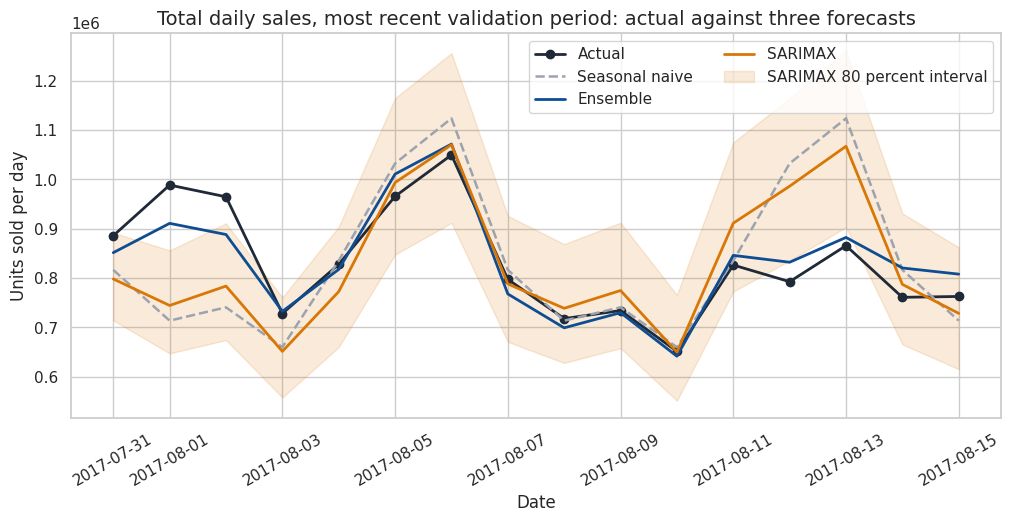

In [31]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(total_fold_one.index, total_fold_one["sales"], color=COLORS["actual"], marker="o", linewidth=2, label="Actual")
ax.plot(total_fold_one.index, total_fold_one["naive"], color=COLORS["naive"], linestyle="--", linewidth=1.8, label="Seasonal naive")
ax.plot(total_fold_one.index, total_fold_one["ensemble"], color=COLORS["gbm"], linewidth=2, label="Ensemble")
ax.plot(total_fold_one.index, total_fold_one["sarimax"], color=COLORS["sarimax"], linewidth=2, label="SARIMAX")
ax.fill_between(total_fold_one.index, total_fold_one["ci_lower y"], total_fold_one["ci_upper y"],
                color=COLORS["sarimax"], alpha=0.15, label="SARIMAX 80 percent interval")
ax.set_title("Total daily sales, most recent validation period: actual against three forecasts")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend(ncol=2)
plt.xticks(rotation=30)
plt.show()
save_fig(fig, "total_level_comparison.png")

**How to read it:** the black line is what really happened. The closer a coloured line follows it, especially on weekends and paydays, the better that method. The shaded band is the range SARIMAX expected 80 percent of days to fall in, which is useful for planning safety stock.

### Residual check
A good ARIMA model leaves residuals (errors) that look like random noise. If patterns remain, the model has missed some structure. We check this on the model fitted for the most recent fold.

Ljung Box test on 14 lags, p value: 0.2502


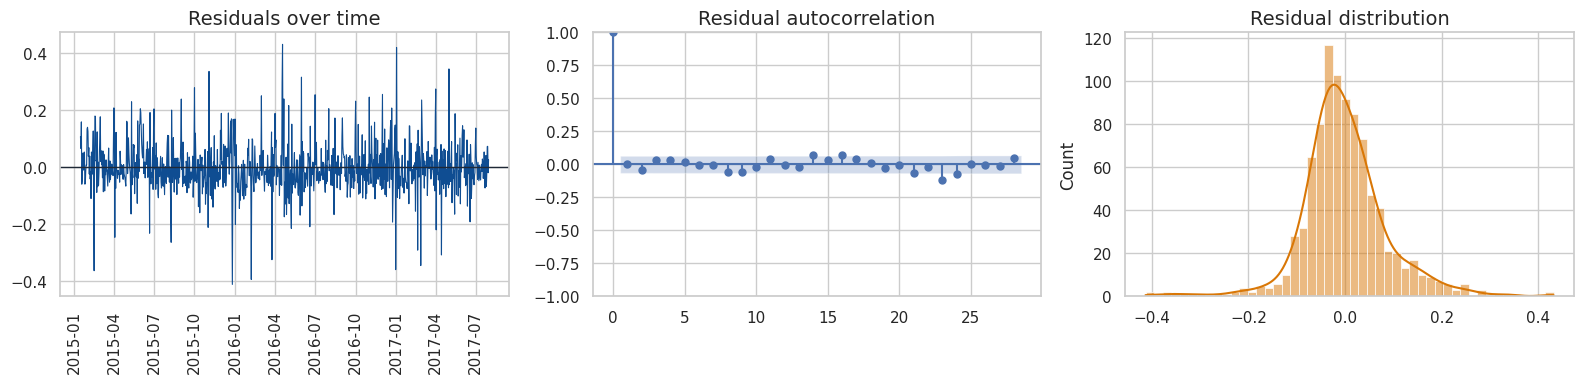

In [32]:
check_result, _, _ = sarimax_forecast(daily_total, folds[0]["origin"], *total_best)
residuals = check_result.resid.iloc[14:].dropna()   # skip the warm up days and the closed days left as missing
ljung = acorr_ljungbox(residuals, lags=[14], return_df=True)
print("Ljung Box test on 14 lags, p value:", round(float(ljung["lb_pvalue"].iloc[0]), 4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(residuals.index, residuals.values, color=COLORS["gbm"], linewidth=0.8)
axes[0].axhline(0, color=COLORS["actual"], linewidth=1)
axes[0].tick_params(axis="x", labelrotation=90)
axes[0].set_title("Residuals over time")
plot_acf(residuals, lags=28, ax=axes[1])
axes[1].set_title("Residual autocorrelation")
sns.histplot(residuals, kde=True, color=COLORS["sarimax"], ax=axes[2])
axes[2].set_title("Residual distribution")
plt.tight_layout()
plt.show()
save_fig(fig, "sarimax_residuals.png")

**How to read it:** residuals should hover around zero with no obvious pattern, show no strong bars in the autocorrelation plot, and look roughly bell shaped. The Ljung Box p value above 0.05 means there is no strong evidence of leftover structure. Failing this check does not make the forecast useless, but it tells you where the model could improve, for example with more regressors for special events.

## 13. SARIMAX on one store
The same method is now applied to a single store, to see how it behaves on a smaller and noisier series. The store with the highest recent sales is used, since it has the most stable pattern. Everything below reuses the functions already written, which is the advantage of keeping the code in functions.

In [33]:
recent_window = train["date"] > (last_train_date - pd.Timedelta(days=365))
top_store = int(train.loc[recent_window].groupby("store_nbr")["sales"].sum().idxmax())
store_info_row = stores.loc[stores["store_nbr"] == top_store].iloc[0]
print(f"Selected store {top_store}: type {store_info_row['type']}, city {store_info_row['city']}")

daily_store = make_daily_frame(frame.loc[frame["store_nbr"] == top_store])
store_order_table, store_best = select_order(daily_store, selection_end)
print("Best candidate by AIC for this store:", store_best)
store_order_table

Selected store 44: type A, city Quito
Best candidate by AIC for this store: ((1, 1, 1), (0, 1, 1, 7))


,order,seasonal_order,AIC
0,"(1, 1, 1)","(0, 1, 1, 7)",-1146.2
1,"(1, 1, 2)","(0, 1, 1, 7)",-1146.0
2,"(1, 1, 1)","(1, 1, 1, 7)",-1145.6
3,"(2, 1, 1)","(0, 1, 1, 7)",-1144.9
4,"(0, 1, 1)","(0, 1, 1, 7)",-1036.1


fold,Fold 1,Fold 2,Fold 3,Fold 4,Average
model,,,,,
Ensemble average,0.0753,0.0781,0.0613,0.0691,0.0710
Ensemble plus SARIMAX,0.0985,0.0522,0.0608,0.0677,0.0698
Gradient boosting,0.0793,0.0987,0.0724,0.0742,0.0812
SARIMAX,0.1236,0.0385,0.0662,0.0909,0.0798
Seasonal naive,0.1418,0.0351,0.0953,0.1110,0.0958


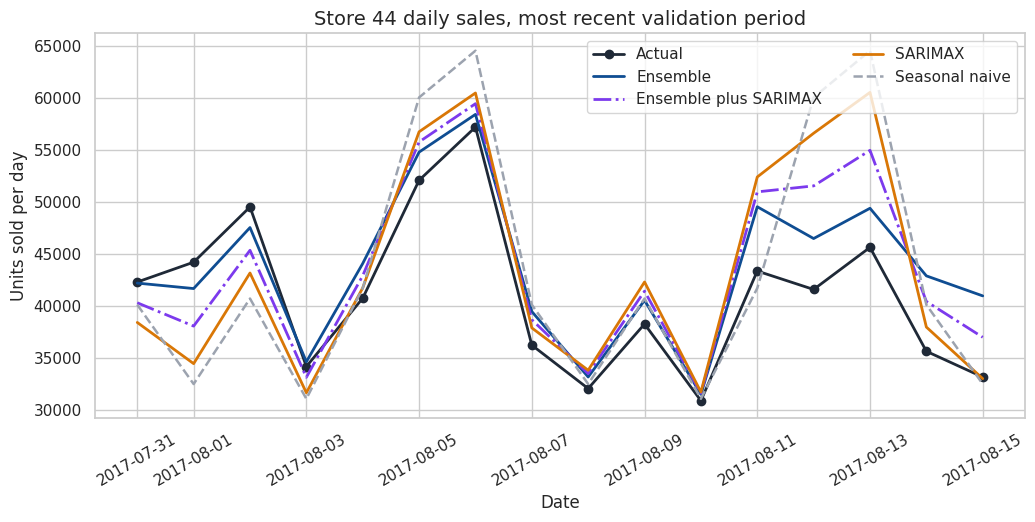

In [34]:
store_comparison, store_fold_one = compare_at_level(daily_store, *store_best, selector=top_store)
display(store_comparison.pivot(index="model", columns="fold", values="WAPE").round(4).assign(Average=lambda d: d.mean(axis=1).round(4)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(store_fold_one.index, store_fold_one["sales"], color=COLORS["actual"], marker="o", linewidth=2, label="Actual")
ax.plot(store_fold_one.index, store_fold_one["ensemble"], color=COLORS["gbm"], linewidth=2, label="Ensemble")
ax.plot(store_fold_one.index, store_fold_one["blend"], color="#7c3aed", linewidth=2, linestyle="-.", label="Ensemble plus SARIMAX")
ax.plot(store_fold_one.index, store_fold_one["sarimax"], color=COLORS["sarimax"], linewidth=2, label="SARIMAX")
ax.plot(store_fold_one.index, store_fold_one["naive"], color=COLORS["naive"], linestyle="--", linewidth=1.8, label="Seasonal naive")
ax.set_title(f"Store {top_store} daily sales, most recent validation period")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend(ncol=2)
plt.xticks(rotation=30)
plt.show()
save_fig(fig, "store_level_comparison.png")

**How to read it:** compare the average column for each method. A single store is noisier than the chain total, so every method makes bigger percentage errors. In our run SARIMAX was competitive with the single gradient boosting model at this level, and the blend of the ensemble with SARIMAX was best by a small margin, though with four folds that margin is within noise.

**Practical conclusion for the business:** the tree ensemble is the production forecast because it scales to every store and family, and it was the most accurate at the chain level. SARIMAX is valuable for a different reason. It is explainable, it needs very little data, and it gives a confidence range, and at a single store it holds its own. Use each where it fits.


## 14. Final forecast
The three ensemble members and SARIMAX are retrained on all available history, then forecast the 16 real test days. Because every feature is at least 16 days old, the tree models forecast all 16 days in one pass without feeding their own predictions back in, so errors do not pile up from day to day. The final forecast for each store and family is the average of the three members, and it covers every one of the 16 days.

In [35]:

final_rows = frame.loc[trainable]
final_models = {"gbm_log": fit_gbm(final_rows), "lgbm_tweedie": fit_lgbm(final_rows), "gbm_recent": fit_gbm_recent(final_rows)}
future_rows = frame.loc[~frame["is_train"]].copy()
future_rows["forecast"] = (predict_gbm(final_models["gbm_log"], future_rows)
                           + predict_lgbm(final_models["lgbm_tweedie"], future_rows)
                           + predict_gbm(final_models["gbm_recent"], future_rows)) / 3

# Save the three models with the information needed to use them again.
import joblib
joblib.dump({"models": final_models, "feature_columns": feature_columns, "categorical_names": categorical_names,
             "family_to_code": family_to_code, "horizon": HORIZON, "last_training_date": last_train_date},
            OUT_DIR / "ensemble_models.joblib")


# Build the submission in the required format using the original test ids.
forecast_long = future_rows[["date", "store_nbr", "family_code", "forecast"]]
submission = test_keys.merge(forecast_long, on=["date", "store_nbr", "family_code"], how="left")
print("Test rows without a forecast:", int(submission["forecast"].isna().sum()))
submission["sales"] = submission["forecast"].fillna(0)
submission[["id", "sales"]].to_csv(OUT_DIR / "submission.csv", index=False)

detailed = submission.assign(family=submission["family_code"].map(code_to_family))
detailed[["id", "date", "store_nbr", "family", "sales"]].rename(columns={"sales": "forecast_units"}).to_csv(
    OUT_DIR / "forecast_by_store_and_family.csv", index=False)

# SARIMAX: refit on all history and forecast the same dates for the chain total.
final_sarimax, sarimax_total_forecast, sarimax_total_interval = sarimax_forecast(daily_total, last_train_date, *total_best)
ensemble_total_forecast = forecast_long.groupby("date")["forecast"].sum()
print(submission["date"].nunique(), "days and", len(submission), "rows forecast")
print("Files saved to:", OUT_DIR.resolve())

Test rows without a forecast: 0
16 days and 28512 rows forecast
Files saved to: /kaggle/working/outputs


In [36]:
HISTORY_DAYS = 365        # how much real history to show next to the forecast, lower this for a smaller file
store_attributes = stores.rename(columns={"type": "store_type"})[["store_nbr", "city", "state", "store_type", "cluster"]]
cutoff_idx = all_dates.get_loc(last_train_date) - HISTORY_DAYS

# Real sales for the recent past.
history_part = frame.loc[frame["is_train"] & frame["is_open_period"] & (frame["date_idx"] > cutoff_idx),
                         ["date", "store_nbr", "family_code", "sales", "onpromotion", "is_holiday"]].rename(columns={"sales": "actual_sales"})
history_part["forecast_units"] = np.nan
history_part["record_type"] = "Actual"

# The 16 forecast days.
forecast_part = future_rows[["date", "store_nbr", "family_code", "onpromotion", "is_holiday", "forecast"]].rename(columns={"forecast": "forecast_units"})
forecast_part["actual_sales"] = np.nan
forecast_part["record_type"] = "Forecast"

powerbi = pd.concat([history_part, forecast_part], ignore_index=True)
powerbi["family"] = powerbi["family_code"].map(code_to_family)
powerbi = powerbi.merge(store_attributes, on="store_nbr", how="left")
powerbi["units"] = powerbi["actual_sales"].fillna(powerbi["forecast_units"])     # one column to plot for both parts
powerbi_columns = ["date", "record_type", "store_nbr", "city", "state", "store_type", "cluster", "family",
                   "units", "actual_sales", "forecast_units", "onpromotion", "is_holiday"]
powerbi = powerbi[powerbi_columns].round({"units": 2, "actual_sales": 2, "forecast_units": 2})
powerbi.to_csv(OUT_DIR / "powerbi_sales_forecast.csv", index=False)

# Accuracy by product family and by store type, using the ensemble over all four validation folds.
validation_all = pd.concat([df.assign(fold=name) for name, df in fold_predictions.items()], ignore_index=True)
validation_all = validation_all.merge(store_attributes[["store_nbr", "store_type"]], on="store_nbr", how="left")
validation_all["family"] = validation_all["family_code"].map(code_to_family)
validation_all["abs_error"] = (validation_all["sales"] - validation_all["ensemble"]).abs()
pieces = []
for group_type, column in [("Product family", "family"), ("Store type", "store_type")]:
    summary = (validation_all.groupby(column).agg(actual_sales=("sales", "sum"), abs_error=("abs_error", "sum"))
               .reset_index().rename(columns={column: "group"}))
    summary.insert(0, "group_type", group_type)
    pieces.append(summary)
accuracy = pd.concat(pieces, ignore_index=True)
accuracy["wape"] = accuracy["abs_error"] / accuracy["actual_sales"].clip(lower=1)
accuracy["share_of_sales"] = accuracy["actual_sales"] / accuracy.groupby("group_type")["actual_sales"].transform("sum")
accuracy.round(4).to_csv(OUT_DIR / "powerbi_accuracy_by_group.csv", index=False)

# Model comparison at all three levels in one table.
comparison = pd.concat([results.assign(level="Store and family"),
                        total_comparison.assign(level="Chain total"),
                        store_comparison.assign(level=f"Store {top_store}")], ignore_index=True)
comparison.round(4).to_csv(OUT_DIR / "powerbi_model_comparison.csv", index=False)

print(f"Main file: {len(powerbi):,} rows, {powerbi['date'].nunique()} days, record types: {powerbi['record_type'].unique().tolist()}")
print("Accuracy file rows:", len(accuracy), "| Comparison file rows:", len(comparison))

Main file: 670,791 rows, 381 days, record types: ['Actual', 'Forecast']
Accuracy file rows: 38 | Comparison file rows: 60


## 15. Business visualizations
Three views for three audiences. The chain total is for buying and cash planning. The store view is for local managers. The product family view is for category and promotion planning.

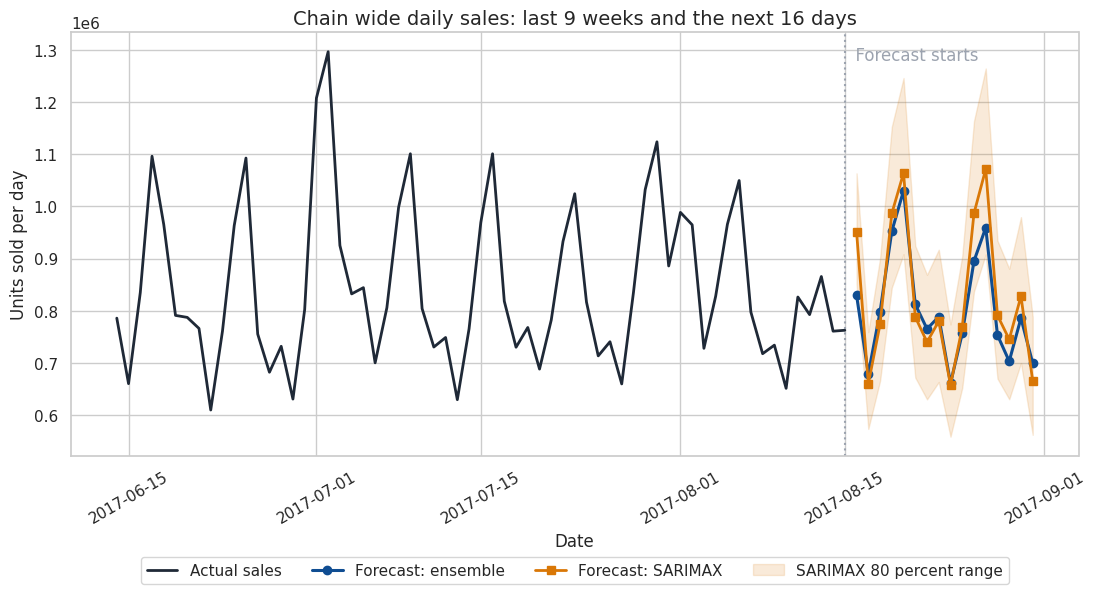

In [37]:
recent_actual = daily_total.loc[last_train_date - pd.Timedelta(days=62):last_train_date, "sales"]

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(recent_actual.index, recent_actual.values, color=COLORS["actual"], linewidth=2, label="Actual sales")
ax.plot(ensemble_total_forecast.index, ensemble_total_forecast.values, color=COLORS["gbm"], marker="o", linewidth=2.2, label="Forecast: ensemble")
ax.plot(sarimax_total_forecast.index, sarimax_total_forecast.values, color=COLORS["sarimax"], marker="s", linewidth=2, label="Forecast: SARIMAX")
ax.fill_between(sarimax_total_interval.index, sarimax_total_interval["lower y"], sarimax_total_interval["upper y"],
                color=COLORS["sarimax"], alpha=0.15, label="SARIMAX 80 percent range")
ax.axvline(last_train_date, color=COLORS["naive"], linestyle=":", linewidth=1.5)
ax.text(last_train_date, ax.get_ylim()[1] * 0.98, "  Forecast starts", color=COLORS["naive"], va="top")
ax.set_title("Chain wide daily sales: last 9 weeks and the next 16 days")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold per day")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
plt.xticks(rotation=30)
plt.show()
save_fig(fig, "forecast_total.png")

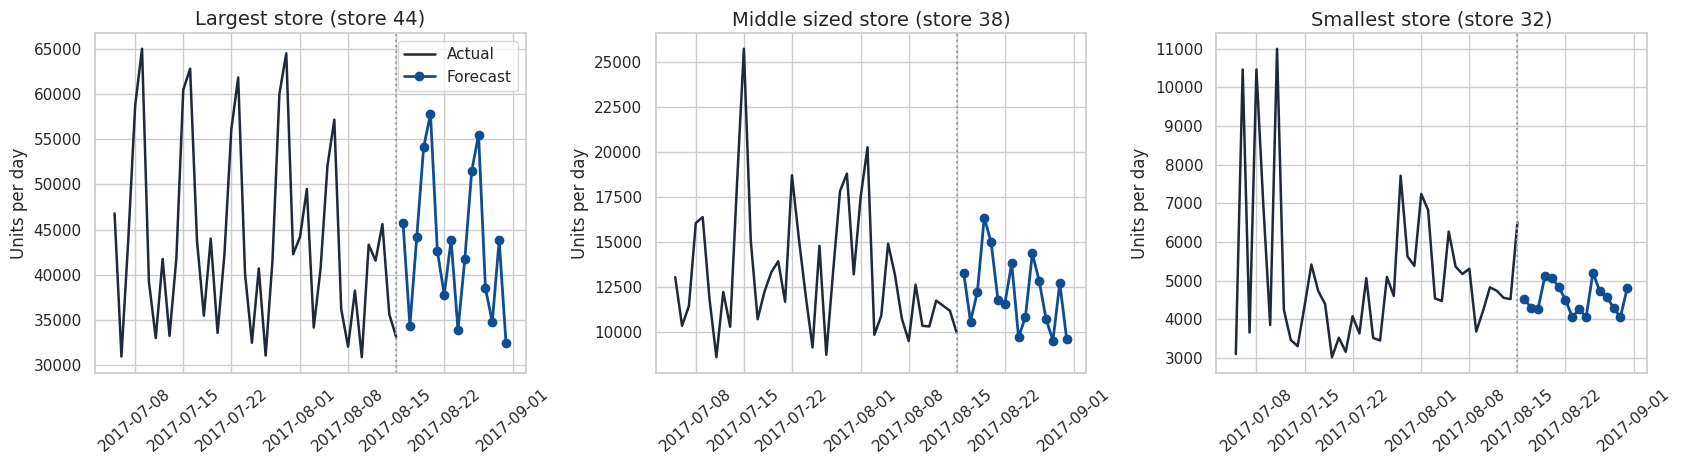

In [38]:
# Example stores: the largest, a middle sized one and the smallest, to show the forecast at different scales.
recent_store_sales = train.loc[recent_window].groupby("store_nbr")["sales"].sum().sort_values(ascending=False)
example_stores = [int(recent_store_sales.index[0]), int(recent_store_sales.index[len(recent_store_sales) // 2]), int(recent_store_sales.index[-1])]
labels = ["Largest store", "Middle sized store", "Smallest store"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, store, label in zip(axes, example_stores, labels):
    history_store = (train[(train["store_nbr"] == store) & (train["date"] > last_train_date - pd.Timedelta(days=42))]
                     .groupby("date")["sales"].sum())
    forecast_store = forecast_long[forecast_long["store_nbr"] == store].groupby("date")["forecast"].sum()
    ax.plot(history_store.index, history_store.values, color=COLORS["actual"], linewidth=1.8, label="Actual")
    ax.plot(forecast_store.index, forecast_store.values, color=COLORS["gbm"], marker="o", linewidth=2, label="Forecast")
    ax.axvline(last_train_date, color=COLORS["naive"], linestyle=":", linewidth=1.5)
    ax.set_title(f"{label} (store {store})")
    ax.set_ylabel("Units per day")
    ax.tick_params(axis="x", rotation=40)
axes[0].legend()
plt.tight_layout()
plt.show()
save_fig(fig, "forecast_example_stores.png")

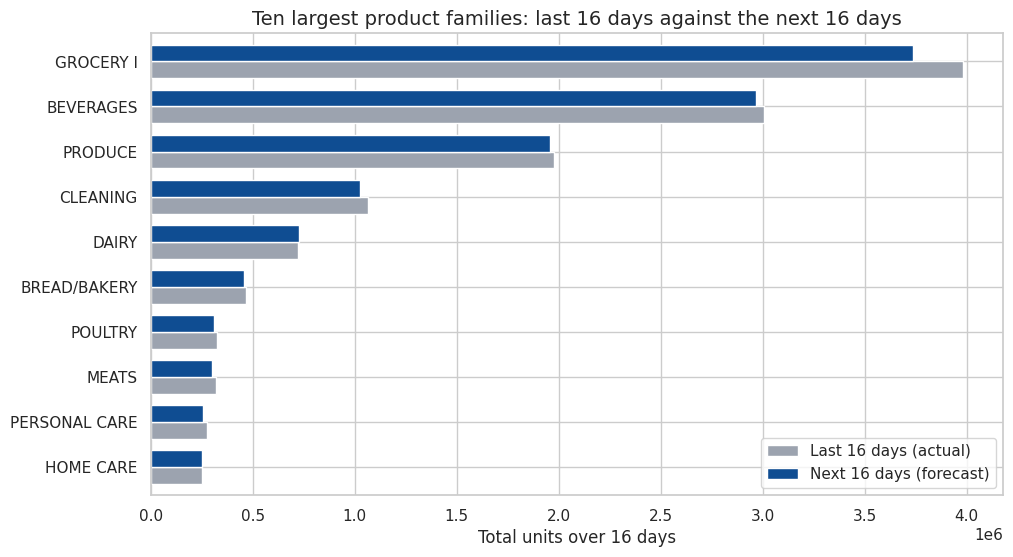

In [39]:
# Expected volume by product family over the 16 forecast days, against the same number of days just before.
previous_window = train[train["date"] > last_train_date - pd.Timedelta(days=HORIZON)]
previous_by_family = previous_window.groupby("family_code")["sales"].sum()
forecast_by_family = forecast_long.groupby("family_code")["forecast"].sum()
family_compare = pd.DataFrame({"Last 16 days (actual)": previous_by_family, "Next 16 days (forecast)": forecast_by_family})
family_compare.index = family_compare.index.map(code_to_family)
family_compare = family_compare.sort_values("Next 16 days (forecast)", ascending=False).head(10)[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
family_compare.plot(kind="barh", ax=ax, color=[COLORS["naive"], COLORS["gbm"]], width=0.75)
ax.set_title("Ten largest product families: last 16 days against the next 16 days")
ax.set_xlabel("Total units over 16 days")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.show()
save_fig(fig, "forecast_families.png")

## 16. Business summary
The code below turns the forecast into the headline numbers a manager would read. The text after it explains how to use them.

In [40]:
actual_previous = daily_total.loc[last_train_date - pd.Timedelta(days=HORIZON - 1):last_train_date, "sales"].sum()
expected_next = ensemble_total_forecast.sum()
busiest_day = ensemble_total_forecast.idxmax()
quietest_day = ensemble_total_forecast.idxmin()
chain_error = total_comparison[total_comparison["model"] == "Ensemble average"]["WAPE"].mean()
detail_error = results[results["model"] == "Ensemble average"]["WAPE"].mean()
sarimax_gap = 100 * (sarimax_total_forecast.sum() / expected_next - 1)
family_forecast_totals = forecast_by_family.rename(index=code_to_family).sort_values(ascending=False)
top3_share = family_forecast_totals.head(3).sum() / family_forecast_totals.sum()

print(f"Expected units over the next {HORIZON} days: {expected_next:,.0f}")
print(f"Change against the previous {HORIZON} days: {100 * (expected_next / actual_previous - 1):+.1f} percent")
print(f"Busiest forecast day: {busiest_day.strftime('%A %d %B')} ({ensemble_total_forecast.max():,.0f} units)")
print(f"Quietest forecast day: {quietest_day.strftime('%A %d %B')} ({ensemble_total_forecast.min():,.0f} units)")
print(f"Typical error on the chain daily total in validation (WAPE): {100 * chain_error:.1f} percent")
print(f"Typical error for one store and family on one day (WAPE): {100 * detail_error:.1f} percent")
print(f"Independent SARIMAX forecast of the same total differs by {sarimax_gap:+.1f} percent")
print("Largest families by forecast volume:", ", ".join(family_forecast_totals.head(3).index))
print(f"Share of forecast volume from the top 3 families: {100 * top3_share:.0f} percent")

Expected units over the next 16 days: 12,869,361
Change against the previous 16 days: -3.4 percent
Busiest forecast day: Sunday 20 August (1,029,991 units)
Quietest forecast day: Thursday 24 August (661,170 units)
Typical error on the chain daily total in validation (WAPE): 3.9 percent
Typical error for one store and family on one day (WAPE): 11.6 percent
Independent SARIMAX forecast of the same total differs by +3.0 percent
Largest families by forecast volume: GROCERY I, BEVERAGES, PRODUCE
Share of forecast volume from the top 3 families: 67 percent


### What the forecast means
For every store and product family the ensemble gives an expected number of units on each of the next 16 days. It is the average of three boosted tree models and reflects recent sales levels, the weekly rhythm, paydays, holidays and planned promotions. The chain total is the sum of all those individual forecasts, and an independent SARIMAX forecast of the chain total serves as a sanity check. If the two totals are close, that adds confidence. If they differ a lot, find out why before ordering.

### How accurate it is
Errors shrink as you add things up. For one store and product family on one day, the typical miss is the store and family WAPE printed above. For the chain daily total it is several times smaller, because over and under forecasts cancel out. Use the number that matches the decision: the larger error for a single shelf or product, the smaller one for chain wide volume.

### How a business can use it
* **Ordering and inventory.** Use the store and family forecast as the base order quantity, then add a safety margin based on the store and family error above. Families with higher error in the error analysis deserve a larger buffer, and stable families a smaller one.
* **Staffing.** The daily chain and store totals show which days are busiest. Schedule more cashiers and shelf stockers on those days.
* **Promotions.** Promotions are a planned input. Before committing to a promotion plan, test different promotion counts in the model and see the expected impact on volume.
* **Cash flow.** The total forecast gives finance an early view of expected volume for the next two weeks.

### Limitations to be honest about
* The unit is items sold, not money. Revenue needs prices, which are not in the data.
* The three ensemble members share the same features, so a shock none of them can see, such as a natural disaster, a new competitor or a supply problem, will be missed by all three.
* The forecast is built for a 16 day horizon. Accuracy drops for longer horizons, and the models should be retrained as new data arrives.
* Validation used four folds of 16 days, which is a small sample, so small differences between models should not be over interpreted.
* SARIMAX was applied to the chain total and one store only. In validation it did not beat the tree ensemble at the chain level, so it is used as a comparison, a sanity check and a source of confidence ranges, not as the main forecast.

### Recommended next steps
* Add price and stock out information if available, since zero sales can mean no stock rather than no demand.
* Try tuning the gradient boosting settings and adding more holiday window features, such as days to the next holiday.
* Rerun the forecast weekly and track the real error against these validation results.

In [41]:
print(submission["date"].nunique(), "days,", len(submission), "rows")
print(submission.groupby("date")["sales"].sum().round(0))

16 days, 28512 rows
date
2017-08-16     829590.0
2017-08-17     678987.0
2017-08-18     797933.0
2017-08-19     952283.0
2017-08-20    1029991.0
2017-08-21     812312.0
2017-08-22     765228.0
2017-08-23     788672.0
2017-08-24     661170.0
2017-08-25     756483.0
2017-08-26     895296.0
2017-08-27     959235.0
2017-08-28     753435.0
2017-08-29     703258.0
2017-08-30     785836.0
2017-08-31     699653.0
Name: sales, dtype: float64
